# CS 6220 – Homework 3: k-Nearest Neighbor, Neural Networks, Bias–Variance

**Structure of this notebook**

| Section | Content | Report questions |
|---|---|---|
| 0 | Setup (imports, helpers for saving figures/results) | – |
| 1 | **k-NN**: distance functions, `knn_predict`, visualization, training/LOOCV error | Q1–Q5 |
| 2 | **Perceptron**: `train_perceptron` and the learning experiments | Q6–Q8 |
| 3 | **Single neuron**: `train_neuron`, activations/costs, animations, learning rates, gradients | Q6, Q9 |

The MLP gradient-flow experiments (Q10–Q12) are in the separate notebooks in `mnist_runs/`
(executed copies of the demo notebook `HW3-gradient_flow_mnist.ipynb` with different settings).

All figures are also written to `figures/` and all numbers used in the report to `results/results.json`.

## 0. Setup

In [1]:
import json
import os
from collections import Counter
from functools import partial

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
from sklearn.datasets import make_moons

os.makedirs('figures', exist_ok=True)
os.makedirs('results', exist_ok=True)
matplotlib.rcParams['animation.embed_limit'] = 80   # MB, so the jshtml animations are not truncated
RESULTS = {}                                        # everything quoted in the report ends up here


def savefig(fig, name):
    # Save every figure so the report can use exactly what the notebook produced.
    fig.savefig(f'figures/{name}.png', dpi=130, bbox_inches='tight')


CLASS_STYLE = {0: dict(color='tab:blue', marker='o', label='class 0'),
               1: dict(color='tab:orange', marker='^', label='class 1')}

# Part 1: k-Nearest Neighbor

## 1.1 Dataset
Everyone uses the same seed. `X` is a `numpy.ndarray` of shape `(200, 2)` (float64) and `y` a `numpy.ndarray`
of shape `(200,)` (int64). A single test record is therefore a 1-D array of length 2 (`X[i]`) plus an integer label (`y[i]`).

In [2]:
np.random.seed(42)
X, y = make_moons(n_samples=200, noise=0.15)
print('X:', type(X).__name__, X.shape, X.dtype, '| y:', type(y).__name__, y.shape, y.dtype)
print('Class counts:', dict(Counter(y.tolist())))

X: ndarray (200, 2) float64 | y: ndarray (200,) int64
Class counts: {0: 100, 1: 100}


## 1.2 Distance measure: general $L_p$ norm
$d_p(v_1, v_2) = \left(\sum_j |v_{1j} - v_{2j}|^p\right)^{1/p}$, with $p=1$ (Manhattan) and $p=2$ (Euclidean).
The function returns a Python `float` for a pair of vectors. Because it reduces over the last axis it also
broadcasts over arrays of vectors; this is only used by the speed-up helpers in 1.5 (grid and LOOCV), the
reference implementation `knn_predict` calls it pair by pair.

In [3]:
def lp_distance(v1, v2, p=2):
    # |v1 - v2|^p summed over the attributes (last axis), then the p-th root
    diff = np.abs(np.asarray(v1, dtype=float) - np.asarray(v2, dtype=float))
    d = np.sum(diff ** p, axis=-1) ** (1.0 / p)
    return float(d) if np.ndim(d) == 0 else d


euclidean = partial(lp_distance, p=2)
manhattan = partial(lp_distance, p=1)
DISTANCES = {'Euclidean': euclidean, 'Manhattan': manhattan}

print(euclidean(np.array([0, 0]), np.array([3, 4])), manhattan(np.array([0, 0]), np.array([3, 4])))  # 5.0 7.0

5.0 7.0


## 1.3 `knn_predict`

**Neighbour search.** Exact linear scan: compute the distance of the test record to every training record
(one by one), then take the indices of the `k` smallest distances. `argsort(kind='stable')` makes ties in
*distance* deterministic (the record with the lower index wins).

**Tie-breaking of the vote** (needed for even `k`, or more than two classes):
1. majority class among the `k` neighbours;
2. if several classes have the same number of votes, pick the one whose neighbours are *closer in total*
   (smallest sum of distances), i.e. the class that is "more nearby";
3. if that is still tied, pick the class of the single nearest neighbour.

`y_test` is part of the required signature but is deliberately **not** used for the prediction
(that would leak the answer); the caller compares the prediction with `y_test`.

In [4]:
def majority_vote(neighbor_labels, neighbor_dists):
    # neighbor_labels / neighbor_dists are sorted by increasing distance
    votes = Counter(neighbor_labels.tolist())
    top = max(votes.values())
    tied = [c for c, v in votes.items() if v == top]
    if len(tied) == 1:
        return int(tied[0])
    # tie-break 1: smallest total distance of the class's neighbours
    sums = {c: neighbor_dists[neighbor_labels == c].sum() for c in tied}
    best = min(sums.values())
    tied = [c for c in tied if np.isclose(sums[c], best)]
    if len(tied) == 1:
        return int(tied[0])
    # tie-break 2: class of the nearest neighbour among the still-tied classes
    for label in neighbor_labels:
        if label in tied:
            return int(label)


def k_nearest(X_train, X_test, k, distance_func):
    # exact search: check every training record one-by-one
    dists = np.array([distance_func(x, X_test) for x in X_train])
    idx = np.argsort(dists, kind='stable')[:k]
    return idx, dists[idx]


def knn_predict(X_train, y_train, X_test, y_test, k, distance_func):
    # y_test is not used to make the prediction (kept for the required signature)
    idx, d = k_nearest(X_train, X_test, k, distance_func)
    return majority_vote(y_train[idx], d)


# make_moons output can be passed directly; a single record is X[i], y[i]
print('prediction for X[0]:', knn_predict(X, y, X[0], y[0], 3, euclidean), '| true:', y[0])

prediction for X[0]: 0 | true: 0


## 1.4 Speed-up helpers (same algorithm, computed in bulk)
The visualization (10,000 grid points) and the k-sweep with LOOCV (200 values of k) would call the pairwise
distance millions of times. The helpers below compute the full distance matrix once (vectorised when the
distance function supports broadcasting) and then apply **the same** `majority_vote` to each row. The assertion
checks that they give exactly the same answers as `knn_predict`.

In [5]:
def pairwise_distances(A, B, distance_func):
    # D[i, j] = distance_func(A[i], B[j])
    try:
        D = distance_func(A[:, None, :], B[None, :, :])
        if np.shape(D) == (len(A), len(B)):
            return np.asarray(D, dtype=float)
    except Exception:
        pass
    return np.array([[distance_func(a, b) for b in B] for a in A])


def predict_from_distances(D, y_train, k):
    # row i of D holds the distances of query i to all training records
    order = np.argsort(D, axis=1, kind='stable')[:, :k]
    return np.array([majority_vote(y_train[o], D[i, o]) for i, o in enumerate(order)])


rng = np.random.default_rng(0)
Q = rng.uniform(-1.5, 2.5, size=(300, 2))
for name, dist in DISTANCES.items():
    for k in (1, 2, 5, 10):
        fast = predict_from_distances(pairwise_distances(Q, X, dist), y, k)
        slow = np.array([knn_predict(X, y, q, None, k, dist) for q in Q])
        assert (fast == slow).all()
print('bulk helpers agree with knn_predict')

bulk helpers agree with knn_predict


## 1.5 Visualizing a 2-D k-NN model
A regular 100×100 grid covering the data is run through the model; the predicted class colours the background
and the black contour line is the decision boundary. Training records are drawn on top (blue circles = class 0,
orange triangles = class 1).

In [6]:
def plot_knn_model(X_train, y_train, k, distance_func, ax=None, title=None, resolution=100, extra_points=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 4.5))
    pad = 0.4
    xs = np.linspace(X_train[:, 0].min() - pad, X_train[:, 0].max() + pad, resolution)
    ys = np.linspace(X_train[:, 1].min() - pad, X_train[:, 1].max() + pad, resolution)
    xx, yy = np.meshgrid(xs, ys)
    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = predict_from_distances(pairwise_distances(grid, X_train, distance_func), y_train, k).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5], colors=['#d6e4f5', '#fbdcc8'])
    ax.contour(xx, yy, Z, levels=[0.5], colors='k', linewidths=1.2)
    for c, style in CLASS_STYLE.items():
        m = y_train == c
        ax.scatter(X_train[m, 0], X_train[m, 1], s=22, edgecolor='k', linewidth=0.4, **style)
    if extra_points is not None:
        ax.scatter(extra_points[:, 0], extra_points[:, 1], marker='*', s=260, c='lime', edgecolor='k',
                   zorder=5, label='test points')
    ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$')
    ax.set_title(title or f'{k}-NN decision regions')
    ax.legend(loc='lower left', fontsize=8)
    return ax

## 1.6 Training error and leave-one-out test error
* **Training error**: every training record is predicted using the *whole* training set (it is its own neighbour).
* **LOOCV test error**: for each record R, R is the test record and all other records are the training set.

`knn_errors` computes both from one distance matrix (LOOCV = set the diagonal to ∞, i.e. remove R itself).
`knn_errors_reference` is the literal definition with `knn_predict`; they are checked against each other.

In [7]:
def knn_errors(X, y, k, distance_func):
    D = pairwise_distances(X, X, distance_func)
    train_pred = predict_from_distances(D, y, k)
    D_loo = D.copy()
    np.fill_diagonal(D_loo, np.inf)            # record R is never its own neighbour
    test_pred = predict_from_distances(D_loo, y, min(k, len(X) - 1))
    return float(np.mean(train_pred != y)), float(np.mean(test_pred != y))


def knn_errors_reference(X, y, k, distance_func):
    n = len(X)
    train_wrong = sum(knn_predict(X, y, X[i], y[i], k, distance_func) != y[i] for i in range(n))
    test_wrong = 0
    for i in range(n):                         # LOOCV
        keep = np.arange(n) != i
        test_wrong += knn_predict(X[keep], y[keep], X[i], y[i], min(k, n - 1), distance_func) != y[i]
    return train_wrong / n, test_wrong / n


for k in (1, 4, 10):
    assert knn_errors(X, y, k, euclidean) == knn_errors_reference(X, y, k, euclidean)
for name, dist in DISTANCES.items():
    for k in (1, 3, 5, 10):
        tr, te = knn_errors(X, y, k, dist)
        print(f'{name:9s} k={k:2d}: training error {tr:.3f}, LOOCV test error {te:.3f}')

Euclidean k= 1: training error 0.000, LOOCV test error 0.020
Euclidean k= 3: training error 0.010, LOOCV test error 0.010
Euclidean k= 5: training error 0.005, LOOCV test error 0.005
Euclidean k=10: training error 0.005, LOOCV test error 0.010
Manhattan k= 1: training error 0.000, LOOCV test error 0.015
Manhattan k= 3: training error 0.010, LOOCV test error 0.010
Manhattan k= 5: training error 0.010, LOOCV test error 0.010
Manhattan k=10: training error 0.005, LOOCV test error 0.005


## Q3. Predictions for the three test points
For each test point, both distances and k = 1, 3, 5 we report the votes per class and the prediction.

In [8]:
test_points = np.array([(0.40, 0.45), (0.08, 0.78), (0.75, -0.15)])
q3 = []
print(f"{'test point':>15s} {'distance':>10s} {'k':>2s} {'votes c0':>8s} {'votes c1':>8s} {'pred':>5s}   neighbours (index: label, dist)")
for tp in test_points:
    for name, dist in DISTANCES.items():
        for k in (1, 3, 5):
            idx, d = k_nearest(X, tp, k, dist)
            votes = Counter(y[idx].tolist())
            pred = knn_predict(X, y, tp, None, k, dist)
            q3.append(dict(point=tp.tolist(), distance=name, k=k, votes0=votes.get(0, 0), votes1=votes.get(1, 0),
                           pred=pred, neighbours=[(int(i), int(y[i]), round(float(di), 4)) for i, di in zip(idx, d)]))
            nb = ', '.join(f'{i}:{y[i]} ({di:.3f})' for i, di in zip(idx, d))
            print(f'{str(tuple(tp.tolist())):>15s} {name:>10s} {k:2d} {votes.get(0, 0):8d} {votes.get(1, 0):8d} {pred:5d}   {nb}')
        print()
RESULTS['q3'] = q3

     test point   distance  k votes c0 votes c1  pred   neighbours (index: label, dist)
    (0.4, 0.45)  Euclidean  1        1        0     0   64:0 (0.197)
    (0.4, 0.45)  Euclidean  3        1        2     1   64:0 (0.197), 5:1 (0.214), 185:1 (0.243)
    (0.4, 0.45)  Euclidean  5        1        4     1   64:0 (0.197), 5:1 (0.214), 185:1 (0.243), 50:1 (0.254), 108:1 (0.264)

    (0.4, 0.45)  Manhattan  1        1        0     0   64:0 (0.218)
    (0.4, 0.45)  Manhattan  3        1        2     1   64:0 (0.218), 5:1 (0.277), 185:1 (0.290)
    (0.4, 0.45)  Manhattan  5        1        4     1   64:0 (0.218), 5:1 (0.277), 185:1 (0.290), 50:1 (0.335), 108:1 (0.354)

   (0.08, 0.78)  Euclidean  1        0        1     1   78:1 (0.101)
   (0.08, 0.78)  Euclidean  3        2        1     0   78:1 (0.101), 9:0 (0.168), 134:0 (0.173)
   (0.08, 0.78)  Euclidean  5        4        1     0   78:1 (0.101), 9:0 (0.168), 134:0 (0.173), 66:0 (0.179), 93:0 (0.180)

   (0.08, 0.78)  Manhattan  1     

  (0.75, -0.15)  Euclidean  5        2        3     1   52:0 (0.105), 69:1 (0.109), 113:1 (0.122), 180:0 (0.136), 48:1 (0.204)

  (0.75, -0.15)  Manhattan  1        0        1     1   69:1 (0.121)
  (0.75, -0.15)  Manhattan  3        1        2     1   69:1 (0.121), 52:0 (0.147), 113:1 (0.164)
  (0.75, -0.15)  Manhattan  5        2        3     1   69:1 (0.121), 52:0 (0.147), 113:1 (0.164), 180:0 (0.174), 48:1 (0.247)



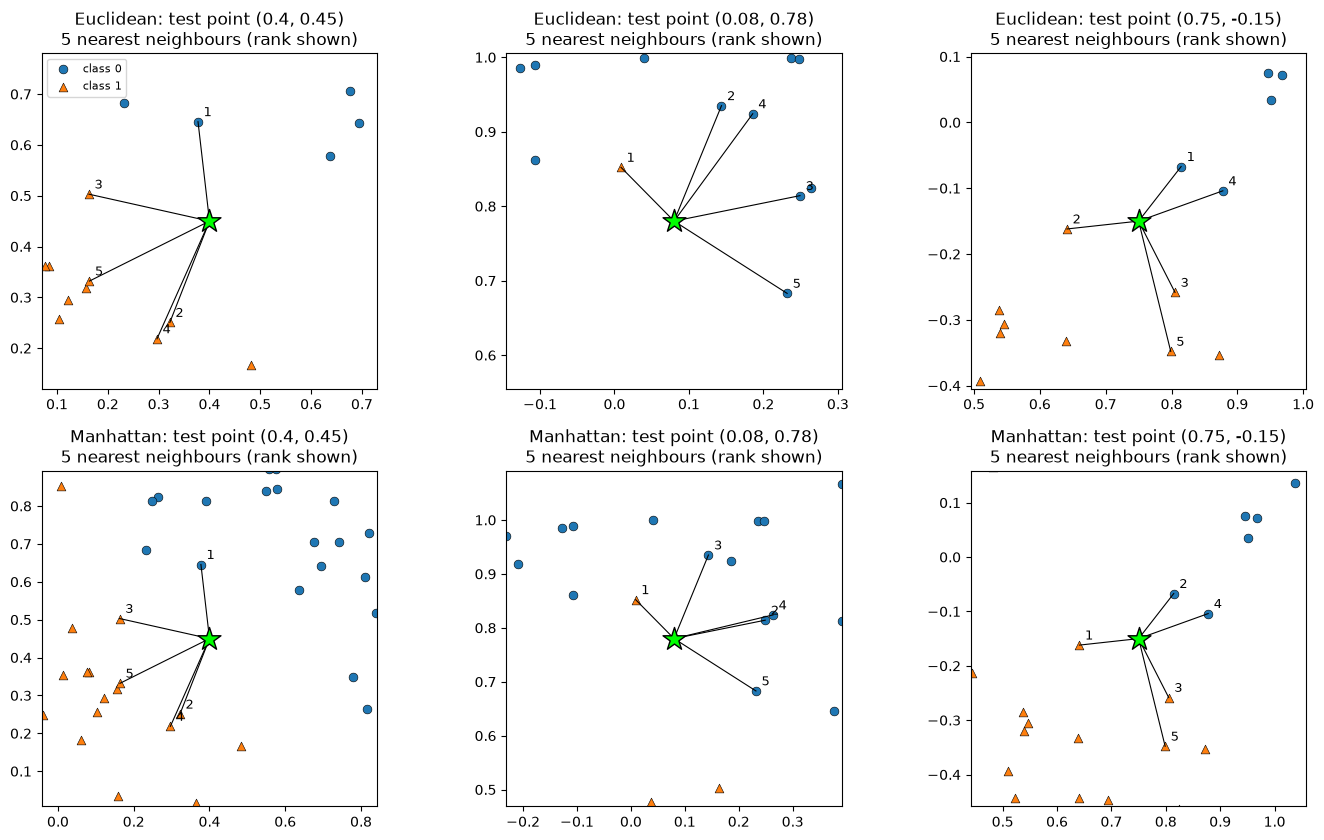

In [9]:
# Zoomed view: the 5 nearest neighbours of every test point under each metric
fig, axes = plt.subplots(2, 3, figsize=(14, 8.5))
for row, (name, dist) in enumerate(DISTANCES.items()):
    for col, tp in enumerate(test_points):
        ax = axes[row, col]
        for c, style in CLASS_STYLE.items():
            m = y == c
            ax.scatter(X[m, 0], X[m, 1], s=40, edgecolor='k', linewidth=0.4, **style)
        idx, d = k_nearest(X, tp, 5, dist)
        for rank, (i, di) in enumerate(zip(idx, d), start=1):
            ax.plot([tp[0], X[i, 0]], [tp[1], X[i, 1]], 'k-', lw=0.8)
            ax.annotate(str(rank), X[i], textcoords='offset points', xytext=(4, 4), fontsize=9)
        ax.scatter(*tp, marker='*', s=300, c='lime', edgecolor='k', zorder=5)
        r = d[-1] * 1.25
        ax.set_xlim(tp[0] - r, tp[0] + r); ax.set_ylim(tp[1] - r, tp[1] + r); ax.set_aspect('equal')
        ax.set_title(f'{name}: test point {tuple(tp.tolist())}\n5 nearest neighbours (rank shown)')
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); savefig(fig, 'q3_neighbours'); plt.show()

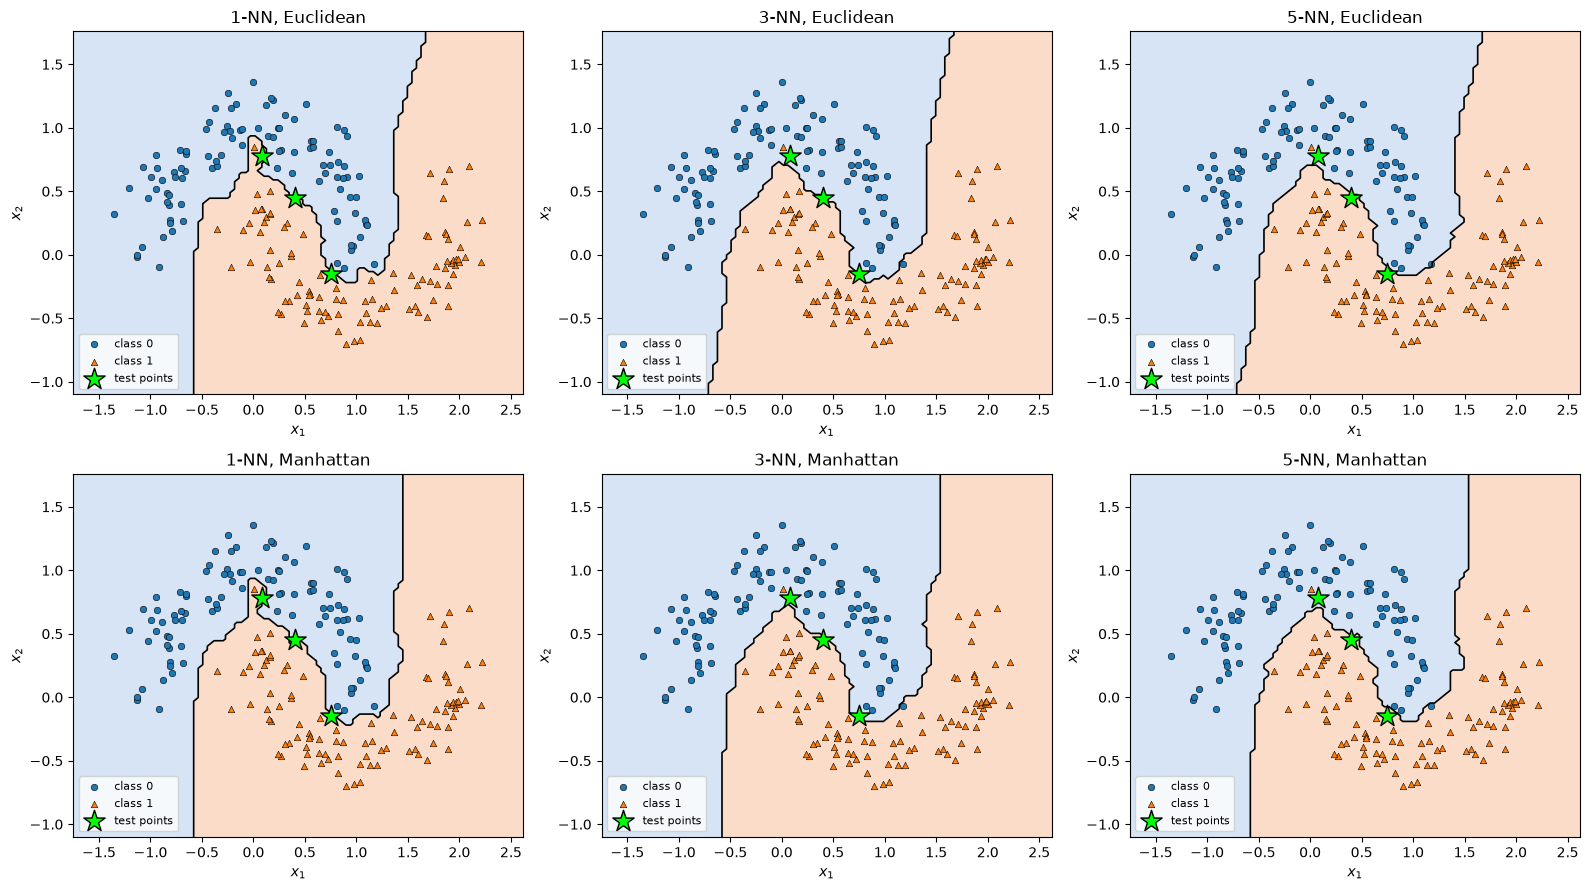

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for row, (name, dist) in enumerate(DISTANCES.items()):
    for col, k in enumerate((1, 3, 5)):
        plot_knn_model(X, y, k, dist, ax=axes[row, col], title=f'{k}-NN, {name}', extra_points=test_points)
plt.tight_layout(); savefig(fig, 'q3_models'); plt.show()

### Q3d. Minimal example where Euclidean and Manhattan disagree
Two training records and one test record suffice (k = 1):
* A = (2, 2), class 0: Euclidean distance to the origin $\sqrt 8 \approx 2.83$, Manhattan distance 4.
* B = (3, 0), class 1: Euclidean distance 3, Manhattan distance 3.
* Test record T = (0, 0).

Euclidean picks A (2.83 < 3) → class 0; Manhattan picks B (3 < 4) → class 1.
Manhattan distance penalises diagonal offsets more than Euclidean, so a point that is "far along both axes"
can be nearest under $L_2$ but not under $L_1$.

Euclidean: d(T,A) = 2.828, d(T,B) = 3.000 -> 1-NN predicts class 0
Manhattan: d(T,A) = 4.000, d(T,B) = 3.000 -> 1-NN predicts class 1


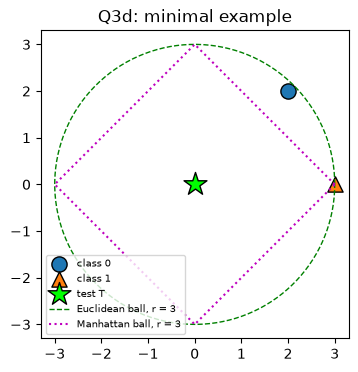

In [11]:
X_min = np.array([[2.0, 2.0], [3.0, 0.0]])
y_min = np.array([0, 1])
T = np.array([0.0, 0.0])
for name, dist in DISTANCES.items():
    print(f'{name:9s}: d(T,A) = {dist(T, X_min[0]):.3f}, d(T,B) = {dist(T, X_min[1]):.3f} '
          f'-> 1-NN predicts class {knn_predict(X_min, y_min, T, None, 1, dist)}')

fig, ax = plt.subplots(figsize=(4.5, 4))
for c, style in CLASS_STYLE.items():
    ax.scatter(*X_min[y_min == c].T, s=120, edgecolor='k', **style)
ax.scatter(*T, marker='*', s=300, c='lime', edgecolor='k', label='test T')
t = np.linspace(0, 2 * np.pi, 400)
ax.plot(3 * np.cos(t), 3 * np.sin(t), 'g--', lw=1, label='Euclidean ball, r = 3')
ax.plot([3, 0, -3, 0, 3], [0, 3, 0, -3, 0], 'm:', lw=1.5, label='Manhattan ball, r = 3')
ax.set_aspect('equal'); ax.legend(fontsize=7, loc='lower left'); ax.set_title('Q3d: minimal example')
savefig(fig, 'q3d_minimal'); plt.show()

## Q4. 1-NN vs. 10-NN (Euclidean)

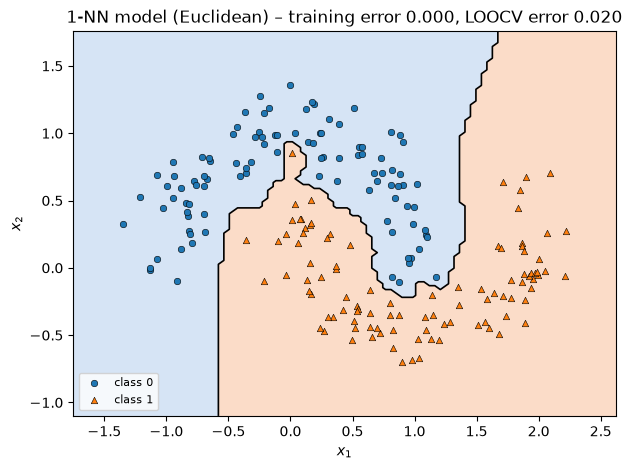

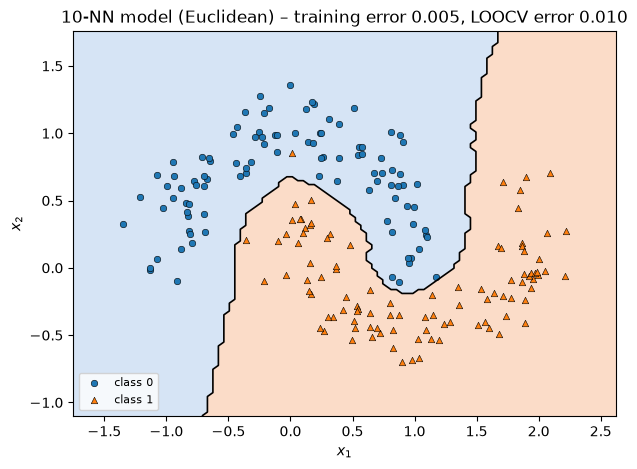

In [12]:
q4 = {}
for k in (1, 10):
    fig, ax = plt.subplots(figsize=(7, 5))
    tr, te = knn_errors(X, y, k, euclidean)
    q4[k] = dict(train_error=tr, loocv_error=te)
    plot_knn_model(X, y, k, euclidean, ax=ax,
                   title=f'{k}-NN model (Euclidean) – training error {tr:.3f}, LOOCV error {te:.3f}')
    savefig(fig, f'q4_{k}nn'); plt.show()
RESULTS['q4'] = q4

## Q5. Training error vs. k

### Q5c. Minimal example where zero training error is impossible
Two records with the **same input but different labels**: (0, 0) → class 0 and (0, 0) → class 1.
Any classifier (k-NN or otherwise) is a function of the input, so it predicts the same class for both records
and at least one of them is wrong: the training error is ≥ 1/2 for every k.

In [13]:
X_c = np.array([[0.0, 0.0], [0.0, 0.0]])
y_c = np.array([0, 1])
for k in (1, 2):
    preds = [knn_predict(X_c, y_c, X_c[i], y_c[i], k, euclidean) for i in range(2)]
    print(f'k={k}: predictions {preds}, true {y_c.tolist()}, training error {np.mean(np.array(preds) != y_c):.2f}')

k=1: predictions [0, 0], true [0, 1], training error 0.50
k=2: predictions [0, 0], true [0, 1], training error 0.50


### Q5d. Sweep k = 1 … n (Euclidean)
For LOOCV only n − 1 = 199 other records exist, so k is capped at 199 there.

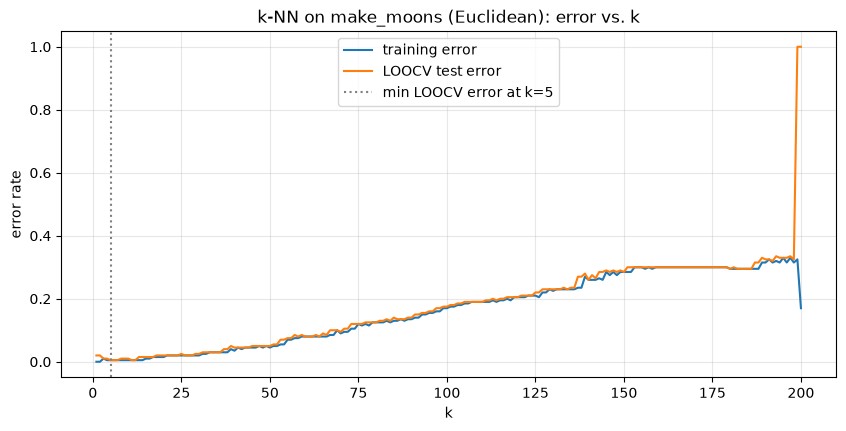

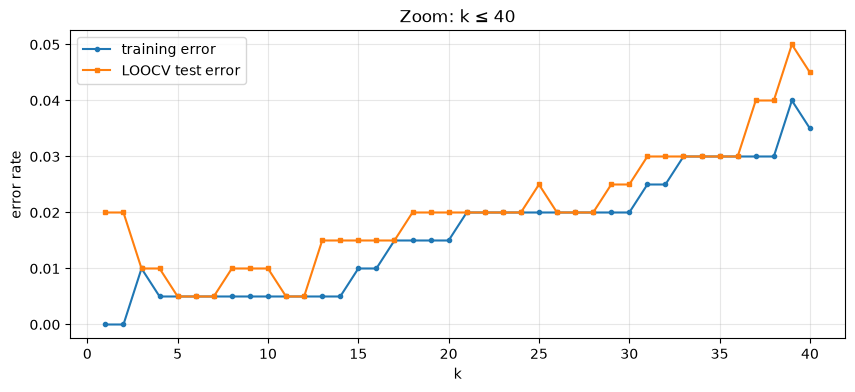

k=  1: train 0.000  LOOCV 0.020
k=  2: train 0.000  LOOCV 0.020
k=  3: train 0.010  LOOCV 0.010
k=  5: train 0.005  LOOCV 0.005
k= 10: train 0.005  LOOCV 0.010
k= 15: train 0.010  LOOCV 0.015
k= 20: train 0.015  LOOCV 0.020
k= 30: train 0.020  LOOCV 0.025
k= 50: train 0.045  LOOCV 0.050
k= 75: train 0.120  LOOCV 0.120
k=100: train 0.170  LOOCV 0.175
k=125: train 0.210  LOOCV 0.220
k=150: train 0.285  LOOCV 0.285
k=175: train 0.300  LOOCV 0.300
k=190: train 0.315  LOOCV 0.325
k=198: train 0.315  LOOCV 0.325
k=199: train 0.325  LOOCV 1.000
k=200: train 0.170  LOOCV 1.000
best k (LOOCV): 5 with error 0.005


In [14]:
n = len(X)
ks = np.arange(1, n + 1)
D = pairwise_distances(X, X, euclidean)
D_loo = D.copy(); np.fill_diagonal(D_loo, np.inf)
order_tr = np.argsort(D, axis=1, kind='stable')
order_te = np.argsort(D_loo, axis=1, kind='stable')
train_err, test_err = [], []
for k in ks:
    ptr = np.array([majority_vote(y[o[:k]], D[i, o[:k]]) for i, o in enumerate(order_tr)])
    kk = min(k, n - 1)
    pte = np.array([majority_vote(y[o[:kk]], D_loo[i, o[:kk]]) for i, o in enumerate(order_te)])
    train_err.append(np.mean(ptr != y)); test_err.append(np.mean(pte != y))
train_err, test_err = np.array(train_err), np.array(test_err)

best = int(ks[np.argmin(test_err)])
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(ks, train_err, label='training error')
ax.plot(ks, test_err, label='LOOCV test error')
ax.axvline(best, color='gray', ls=':', label=f'min LOOCV error at k={best}')
ax.set_xlabel('k'); ax.set_ylabel('error rate'); ax.grid(alpha=0.3); ax.legend()
ax.set_title('k-NN on make_moons (Euclidean): error vs. k')
savefig(fig, 'q5d_error_vs_k'); plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
m = ks <= 40
ax.plot(ks[m], train_err[m], 'o-', ms=3, label='training error')
ax.plot(ks[m], test_err[m], 's-', ms=3, label='LOOCV test error')
ax.set_xlabel('k'); ax.set_ylabel('error rate'); ax.grid(alpha=0.3); ax.legend(); ax.set_title('Zoom: k ≤ 40')
savefig(fig, 'q5d_error_vs_k_zoom'); plt.show()

for k in (1, 2, 3, 5, 10, 15, 20, 30, 50, 75, 100, 125, 150, 175, 190, 198, 199, 200):
    print(f'k={k:3d}: train {train_err[k-1]:.3f}  LOOCV {test_err[k-1]:.3f}')
print('best k (LOOCV):', best, 'with error', test_err[best - 1])
RESULTS['q5d'] = dict(train=train_err.tolist(), test=test_err.tolist(), best_k=best)

# Part 2: Neural Networks

## 2.1 Perceptron
Perceptron output $o = 1$ if $w_1x_1 + w_2x_2 + b > 0$, else $0$.
Training rule for one record $(x_1, x_2, y)$: $w_i \leftarrow w_i + \eta\,(y - o)\,x_i$ and $b \leftarrow b + \eta\,(y-o)$.
Correctly classified records ($y = o$) leave the parameters unchanged.

In [15]:
def perceptron_output(x1, x2, w1, w2, b):
    return 1 if w1 * x1 + w2 * x2 + b > 0 else 0


def train_perceptron(training_record, learning_rate, w1, w2, b):
    x1, x2, y = training_record
    error = y - perceptron_output(x1, x2, w1, w2, b)   # 0 (correct), +1 or -1 (wrong)
    w1 = w1 + learning_rate * error * x1
    w2 = w2 + learning_rate * error * x2
    b = b + learning_rate * error
    return w1, w2, b


def perceptron_error(data, w1, w2, b):
    return float(np.mean([perceptron_output(x1, x2, w1, w2, b) != yy for x1, x2, yy in data]))


def run_perceptron(data, w1, w2, b, learning_rate, max_epochs, stop_when_perfect=True):
    # call 0 = initial parameters; afterwards one entry per train_perceptron call
    hist = [dict(call=0, epoch=0, record=None, w1=w1, w2=w2, b=b, error=perceptron_error(data, w1, w2, b))]
    for epoch in range(1, max_epochs + 1):
        for r, rec in enumerate(data):
            w1, w2, b = train_perceptron(rec, learning_rate, w1, w2, b)
            hist.append(dict(call=len(hist), epoch=epoch, record=r, w1=w1, w2=w2, b=b,
                             error=perceptron_error(data, w1, w2, b)))
        if stop_when_perfect and hist[-1]['error'] == 0:
            break
    return hist


def plot_perceptron(data, w1, w2, b, ax, title, highlight=None):
    data = np.asarray(data, dtype=float)
    xs = np.linspace(0, 4, 200)
    xx, yy = np.meshgrid(xs, xs)
    Z = (w1 * xx + w2 * yy + b > 0).astype(int)
    ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5], colors=['#d6e4f5', '#fbdcc8'])
    if Z.min() != Z.max():
        ax.contour(xx, yy, Z, levels=[0.5], colors='k', linewidths=1.5)
    for c, style in CLASS_STYLE.items():
        m = data[:, 2] == c
        ax.scatter(data[m, 0], data[m, 1], s=45, edgecolor='k', linewidth=0.5, **style)
    if highlight is not None:
        ax.scatter(data[highlight, 0], data[highlight, 1], s=200, facecolor='none', edgecolor='red', lw=2)
    ax.set_xlim(0, 4); ax.set_ylim(0, 4); ax.set_aspect('equal')
    ax.set_title(title, fontsize=9)

## Q7. Perceptron on the linearly separable dataset
Bad initial boundary: $w_1 = w_2 = -0.1$, $b = 0.4$, i.e. the line $x_1 + x_2 = 4$ with the classes on the
wrong sides: it predicts class 1 near (1, 1) and class 0 near (3, 3), so **all 10 records are misclassified**
(error 1.0). Learning rate η = 0.1. (A larger-magnitude version of the same line, $w_1 = w_2 = -1$, $b = 4$, is
also all wrong but needs 180 calls instead of 40, because each update only changes the parameters by
η·x ≈ 0.1–0.3; this is shown at the end of the section.)

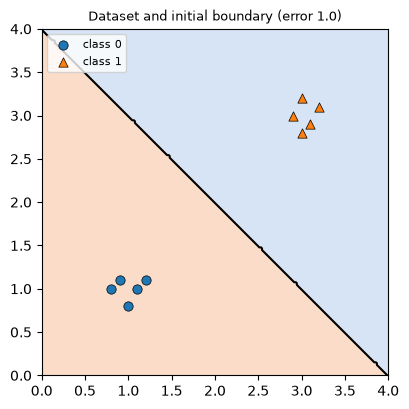

call epoch record       w1       w2        b  error
   0     0   None   -0.100   -0.100    0.400   1.00
   1     1      0   -0.190   -0.210    0.300   0.50
   2     1      1   -0.190   -0.210    0.300   0.50
   3     1      2   -0.190   -0.210    0.300   0.50
   4     1      3   -0.190   -0.210    0.300   0.50
   5     1      4   -0.190   -0.210    0.300   0.50
   6     1      5    0.120    0.080    0.400   0.50
   7     1      6    0.120    0.080    0.400   0.50
   8     1      7    0.120    0.080    0.400   0.50
   9     1      8    0.120    0.080    0.400   0.50
  10     1      9    0.120    0.080    0.400   0.50
  11     2      0    0.030   -0.030    0.300   0.50
  12     2      1   -0.070   -0.110    0.200   0.90
  13     2      2   -0.180   -0.210    0.100   0.50
  14     2      3   -0.180   -0.210    0.100   0.50
  15     2      4   -0.180   -0.210    0.100   0.50
  16     2      5    0.130    0.080    0.200   0.50
  17     2      6    0.130    0.080    0.200   0.50
  18     2  

In [16]:
data7 = [(0.9, 1.1, 0), (1.0, 0.8, 0), (1.1, 1.0, 0), (0.8, 1.0, 0), (1.2, 1.1, 0),
         (3.1, 2.9, 1), (3.0, 3.2, 1), (2.9, 3.0, 1), (3.2, 3.1, 1), (3.0, 2.8, 1)]
W0 = (-0.1, -0.1, 0.4)
LR = 0.1

fig, ax = plt.subplots(figsize=(4.5, 4.5))
plot_perceptron(data7, *W0, ax, f'Dataset and initial boundary (error {perceptron_error(data7, *W0):.1f})')
ax.legend(fontsize=8, loc='upper left'); savefig(fig, 'q7_initial'); plt.show()

hist7 = run_perceptron(data7, *W0, LR, max_epochs=100)
print(f"{'call':>4s} {'epoch':>5s} {'record':>6s} {'w1':>8s} {'w2':>8s} {'b':>8s} {'error':>6s}")
for h in hist7:
    print(f"{h['call']:4d} {h['epoch']:5d} {str(h['record']):>6s} {h['w1']:8.3f} {h['w2']:8.3f} {h['b']:8.3f} {h['error']:6.2f}")
RESULTS['q7_hist'] = hist7

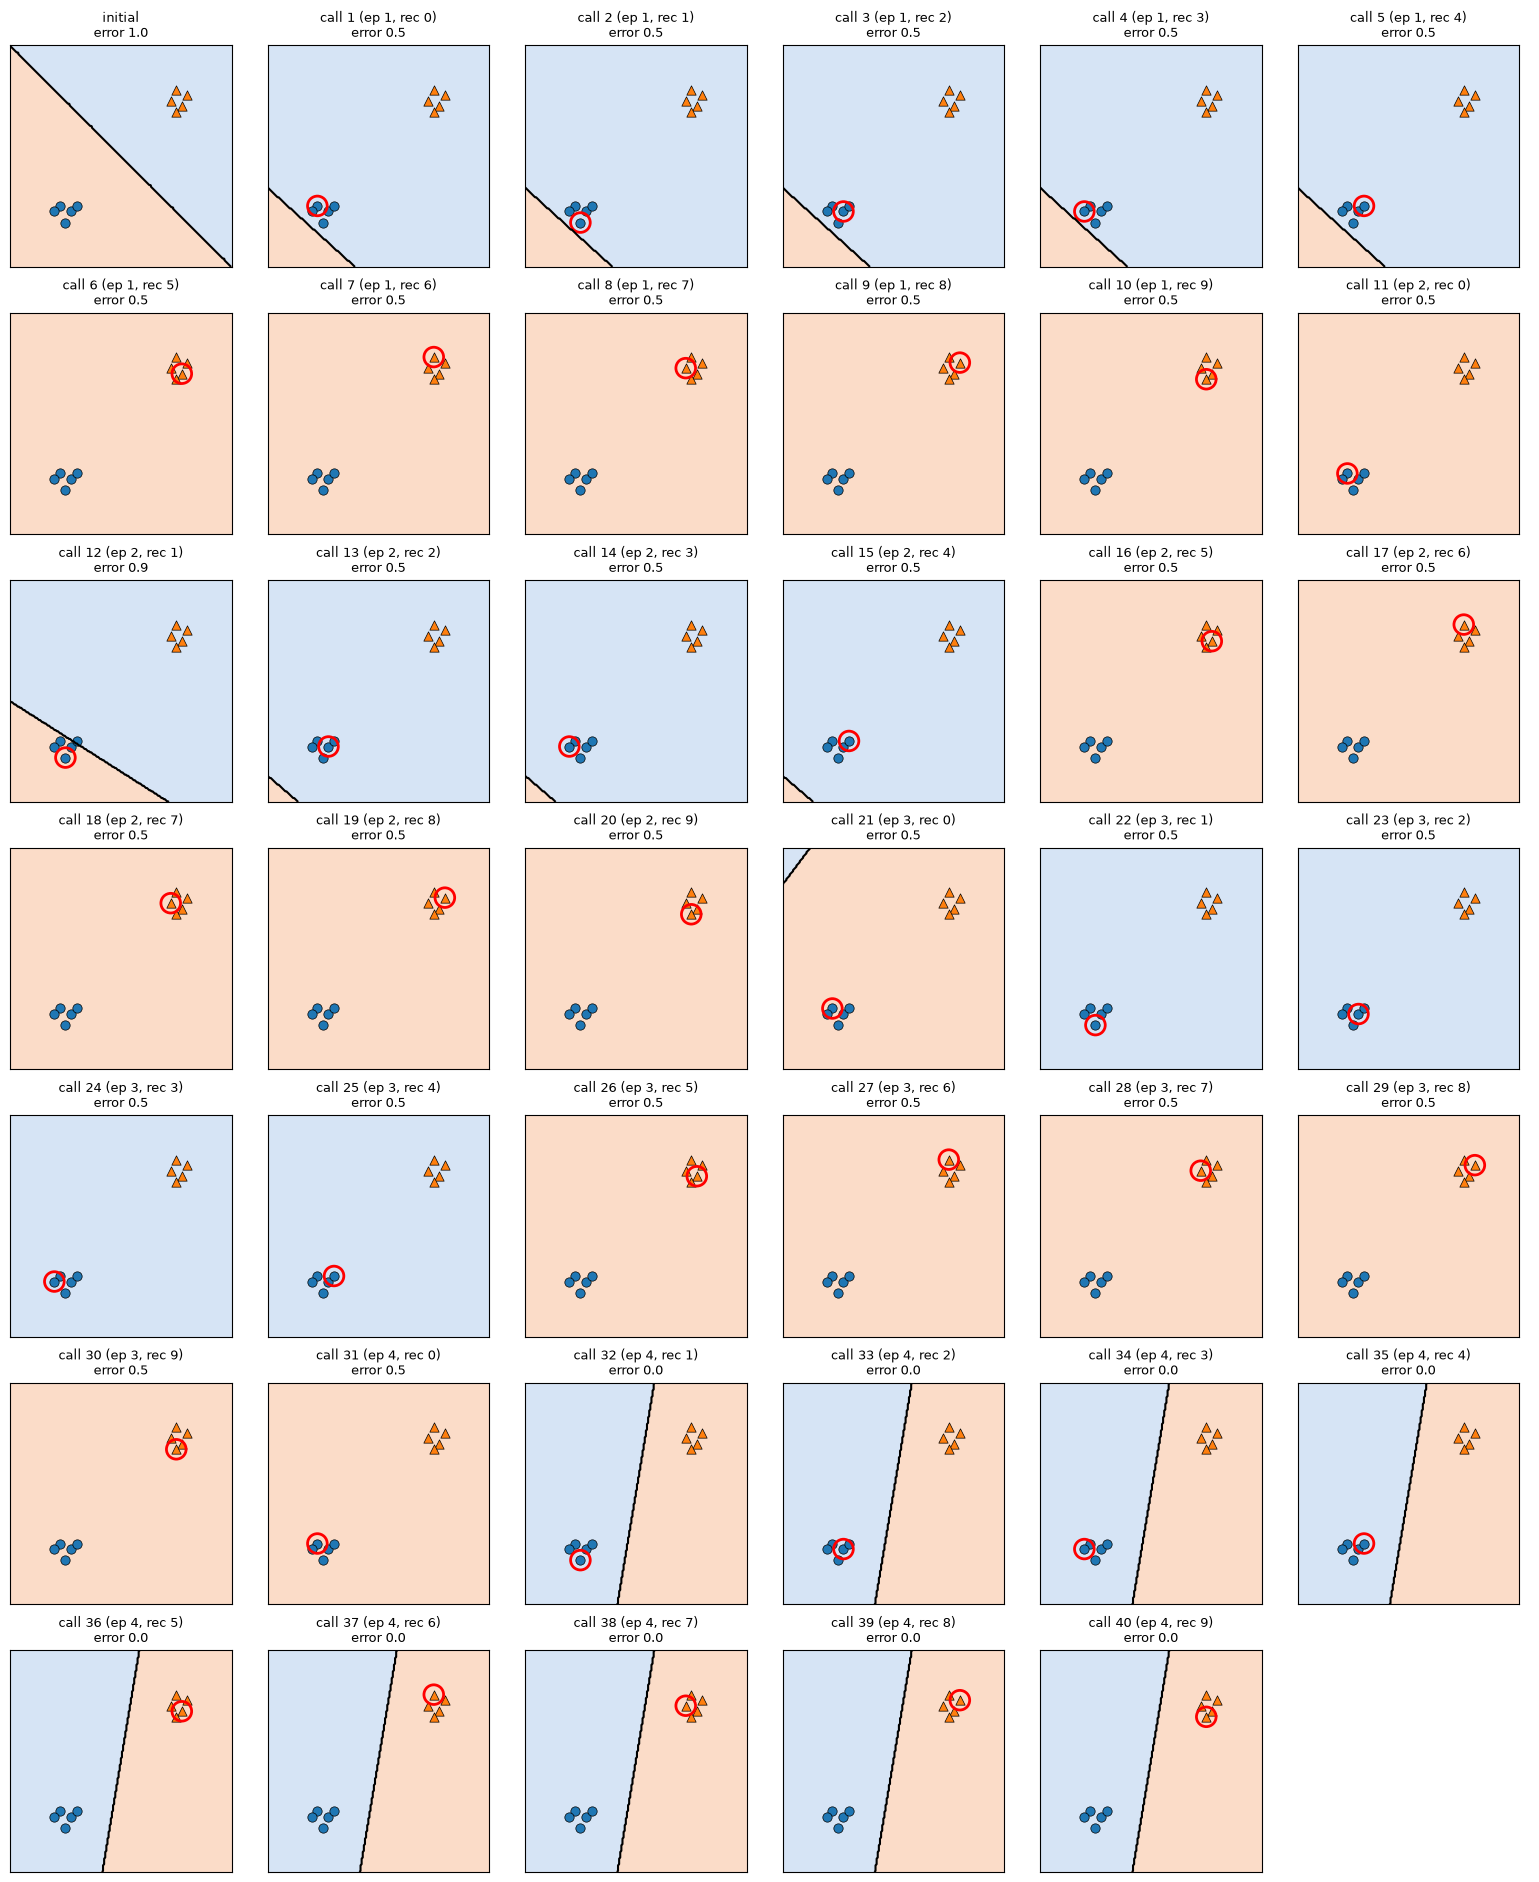

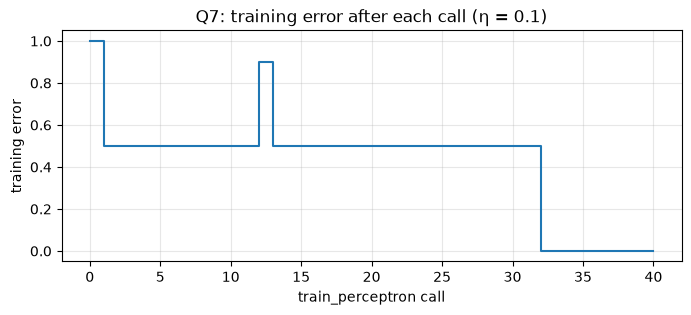

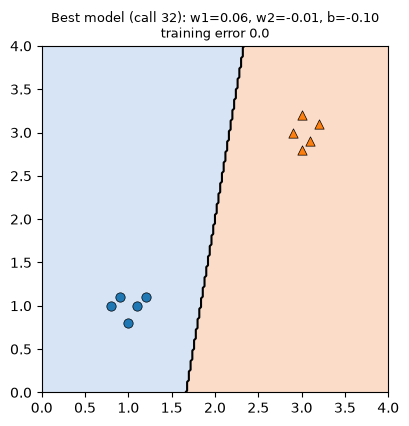

w=(-1,-1), b=4: initial error 1.0, final error 0.0, calls 180, final w1=0.150 w2=-0.020 b=-0.300


In [17]:
# Boundary after every call (each panel = state after the call; red circle = record used in that call)
n_show = len(hist7)
cols = 6
rows = int(np.ceil(n_show / cols))
fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.6, rows * 2.7))
for ax, h in zip(axes.ravel(), hist7):
    t = 'initial' if h['call'] == 0 else f"call {h['call']} (ep {h['epoch']}, rec {h['record']})"
    plot_perceptron(data7, h['w1'], h['w2'], h['b'], ax, f"{t}\nerror {h['error']:.1f}", highlight=h['record'])
    ax.set_xticks([]); ax.set_yticks([])
for ax in axes.ravel()[n_show:]:
    ax.axis('off')
plt.tight_layout(); savefig(fig, 'q7_all_calls'); plt.show()

fig, ax = plt.subplots(figsize=(8, 3))
ax.step([h['call'] for h in hist7], [h['error'] for h in hist7], where='post')
ax.set_xlabel('train_perceptron call'); ax.set_ylabel('training error'); ax.grid(alpha=0.3)
ax.set_title('Q7: training error after each call (η = 0.1)')
savefig(fig, 'q7_error_trace'); plt.show()

best7 = min(hist7, key=lambda h: (h['error'], h['call']))
fig, ax = plt.subplots(figsize=(4.5, 4.5))
plot_perceptron(data7, best7['w1'], best7['w2'], best7['b'], ax,
                f"Best model (call {best7['call']}): w1={best7['w1']:.2f}, w2={best7['w2']:.2f}, b={best7['b']:.2f}\n"
                f"training error {best7['error']:.1f}")
savefig(fig, 'q7_best'); plt.show()
RESULTS['q7_best'] = best7

# same (wrong) line, 10x larger parameters: still converges, but needs many more calls
hist7_big = run_perceptron(data7, -1.0, -1.0, 4.0, LR, max_epochs=100)
print(f"w=(-1,-1), b=4: initial error {hist7_big[0]['error']}, final error {hist7_big[-1]['error']}, "
      f"calls {len(hist7_big) - 1}, final w1={hist7_big[-1]['w1']:.3f} w2={hist7_big[-1]['w2']:.3f} b={hist7_big[-1]['b']:.3f}")
RESULTS['q7_big_calls'] = len(hist7_big) - 1

## Q8. Adding the record (1.0, 1.0, 1)
The new class-1 record lies in the middle of the class-0 cluster, so the data is no longer linearly separable.
We run the same experiment for a fixed 100 epochs (1,100 calls).

initial error: 0.9090909090909091 | minimum error reached: 0.09090909090909091 (= 1/11 records) | error ever 0? False
distinct error values in the last 10 epochs: [0.091, 0.182, 0.273, 0.364, 0.455]
end of epoch   1: w1=0.120 w2=0.080 b=0.400 error=0.455
end of epoch   2: w1=0.130 w2=0.080 b=0.200 error=0.455
end of epoch   3: w1=0.250 w2=0.180 b=0.100 error=0.455
end of epoch   4: w1=0.160 w2=0.090 b=0.000 error=0.455
end of epoch   5: w1=0.170 w2=0.080 b=0.000 error=0.455
end of epoch  96: w1=1.160 w2=-0.300 b=-0.600 error=0.455
end of epoch  97: w1=1.070 w2=-0.390 b=-0.700 error=0.364
end of epoch  98: w1=1.070 w2=-0.370 b=-0.700 error=0.273
end of epoch  99: w1=1.070 w2=-0.350 b=-0.700 error=0.273
end of epoch 100: w1=1.070 w2=-0.330 b=-0.700 error=0.273


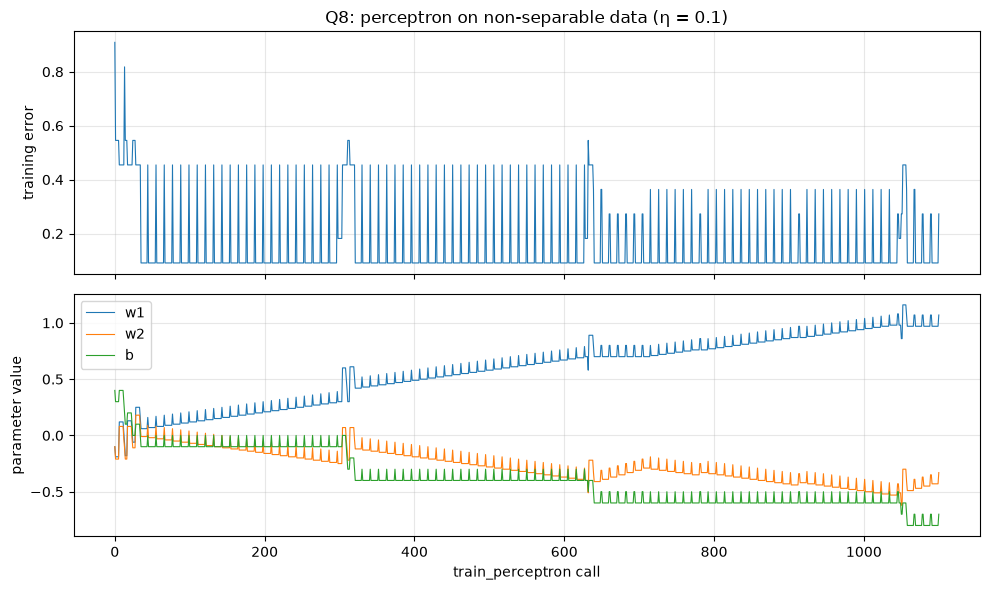

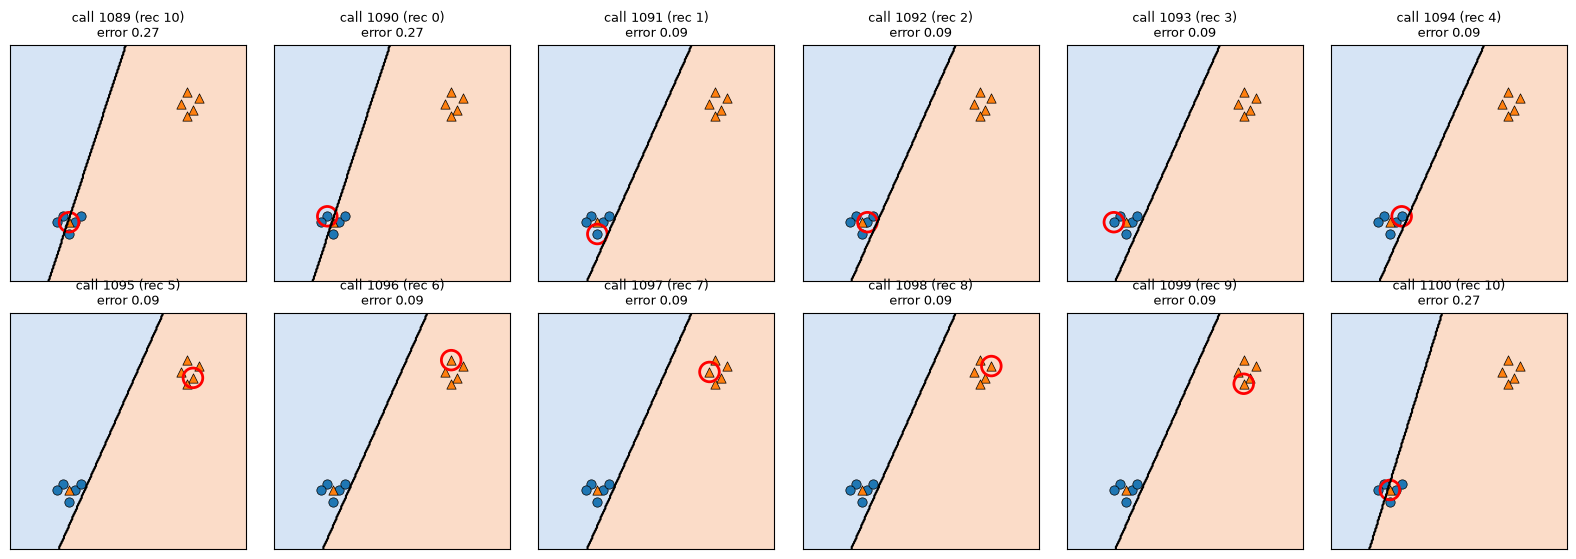

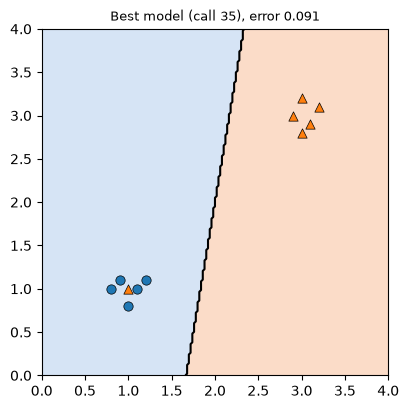

In [18]:
data8 = data7 + [(1.0, 1.0, 1)]
hist8 = run_perceptron(data8, *W0, LR, max_epochs=100, stop_when_perfect=False)
err8 = np.array([h['error'] for h in hist8])
print('initial error:', err8[0], '| minimum error reached:', err8.min(),
      f'(= {int(round(err8.min() * len(data8)))}/{len(data8)} records)', '| error ever 0?', (err8 == 0).any())
print('distinct error values in the last 10 epochs:', sorted(set(np.round(err8[-110:], 3).tolist())))
end_of_epoch = [h for h in hist8 if h['record'] == len(data8) - 1]
for h in end_of_epoch[:5] + end_of_epoch[-5:]:
    print(f"end of epoch {h['epoch']:3d}: w1={h['w1']:.3f} w2={h['w2']:.3f} b={h['b']:.3f} error={h['error']:.3f}")

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(err8, lw=0.8); axes[0].set_ylabel('training error'); axes[0].grid(alpha=0.3)
axes[0].set_title('Q8: perceptron on non-separable data (η = 0.1)')
for key in ('w1', 'w2', 'b'):
    axes[1].plot([h[key] for h in hist8], label=key, lw=0.8)
axes[1].set_xlabel('train_perceptron call'); axes[1].set_ylabel('parameter value'); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); savefig(fig, 'q8_trace'); plt.show()

# a few consecutive calls late in training: the boundary keeps jumping
late = hist8[-12:]
fig, axes = plt.subplots(2, 6, figsize=(16, 5.6))
for ax, h in zip(axes.ravel(), late):
    plot_perceptron(data8, h['w1'], h['w2'], h['b'], ax,
                    f"call {h['call']} (rec {h['record']})\nerror {h['error']:.2f}", highlight=h['record'])
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); savefig(fig, 'q8_late_calls'); plt.show()

best8 = min(hist8, key=lambda h: (h['error'], h['call']))
fig, ax = plt.subplots(figsize=(4.5, 4.5))
plot_perceptron(data8, best8['w1'], best8['w2'], best8['b'], ax,
                f"Best model (call {best8['call']}), error {best8['error']:.3f}")
savefig(fig, 'q8_best'); plt.show()
RESULTS['q8'] = dict(min_error=float(err8.min()), best=best8, ever_zero=bool((err8 == 0).any()),
                     last_epoch_errors=sorted(set(np.round(err8[-110:], 3).tolist())))

## 2.2 Single neuron: `train_neuron`
The neuron computes $z = wx + b$, $a = g(z)$. For one record $(x, y)$ and cost $C(a, y)$ the chain rule gives
$$\delta = \frac{\partial C}{\partial z} = C'(a, y)\, g'(z), \qquad \frac{\partial C}{\partial w} = \delta\,x, \qquad \frac{\partial C}{\partial b} = \delta,$$
followed by the gradient-descent step $w \leftarrow w - \eta\,\partial C/\partial w$, $b \leftarrow b - \eta\,\partial C/\partial b$.

* **Cost derivatives** (w.r.t. the output $a$): squared error $C = \tfrac12 (a-y)^2 \Rightarrow C' = a - y$;
  cross-entropy $C = -[y\ln a + (1-y)\ln(1-a)] \Rightarrow C' = \frac{a-y}{a(1-a)}$ ($a$ is clipped to $[10^{-7}, 1-10^{-7}]$).
* **Activation derivatives** (w.r.t. $z$): sigmoid $\sigma(z)(1-\sigma(z))$, tanh $1-\tanh^2 z$, ReLU $1$ if $z>0$ else $0$
  (0 at $z = 0$ as required), plus linear ($g' = 1$) for Q9e.

The required signature only passes the *derivative* functions, but the forward pass needs $g$ itself.
Each derivative function therefore carries its activation as an attribute (`activation_derivative.activation`).
For Q9d, `train_neuron` can also return the two gradients (`return_gradients=True`).

In [19]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def sigmoid_derivative(z):
    s = sigmoid(z)
    return s * (1.0 - s)

def tanh_derivative(z):
    return 1.0 - np.tanh(z) ** 2

def relu(z):
    return max(0.0, z)

def relu_derivative(z):
    return 1.0 if z > 0 else 0.0          # derivative at 0 set to 0

def linear(z):
    return z

def linear_derivative(z):
    return 1.0

# attach the activation to its derivative so train_neuron can do the forward pass
sigmoid_derivative.activation = sigmoid
tanh_derivative.activation = np.tanh
relu_derivative.activation = relu
linear_derivative.activation = linear

EPS = 1e-7

def squared_error(a, y):
    return 0.5 * (a - y) ** 2

def squared_error_derivative(a, y):
    return a - y

def cross_entropy(a, y):
    a = np.clip(a, EPS, 1 - EPS)
    return -(y * np.log(a) + (1 - y) * np.log(1 - a))

def cross_entropy_derivative(a, y):
    a = np.clip(a, EPS, 1 - EPS)
    return (a - y) / (a * (1 - a))

squared_error_derivative.cost = squared_error
cross_entropy_derivative.cost = cross_entropy

ACTIVATIONS = {'sigmoid': sigmoid_derivative, 'tanh': tanh_derivative, 'relu': relu_derivative, 'linear': linear_derivative}
COSTS = {'squared error': squared_error_derivative, 'cross-entropy': cross_entropy_derivative}


def train_neuron(training_record, learning_rate, w, b, cost_derivative, activation_derivative, return_gradients=False):
    x, y = training_record
    z = w * x + b                                         # forward pass
    a = activation_derivative.activation(z)
    delta = cost_derivative(a, y) * activation_derivative(z)   # dC/dz by the chain rule
    grad_w, grad_b = delta * x, delta
    w = w - learning_rate * grad_w                        # gradient-descent step
    b = b - learning_rate * grad_b
    if return_gradients:
        return w, b, grad_w, grad_b
    return w, b

## Q9. Regression on y = 2x + 3

**Data generator (HW 2).** $x \sim U[0, 1]$, $y = f(x) + \varepsilon$ with Gaussian noise $\varepsilon \sim N(0, 0.1^2)$
("noise level 0.1" = standard deviation of the noise), 100 records, fixed seed.

**Training procedure.** One *epoch* = one call of `train_neuron` for every record (shuffled each epoch, same seed
for every run). Initial parameters $w = b = 0.1$ (positive, so a ReLU unit starts "alive").
Model quality is measured by the MSE between the model's prediction and the data (on the scale of the targets).

**Targets.** The targets lie in [3, 5]. Sigmoid outputs are limited to (0, 1) and tanh outputs to (−1, 1), and
cross-entropy is only defined for targets in [0, 1]. We therefore run every combination twice:
(A) on the **raw** targets and (B) on **rescaled** targets $y' = (y - 3)/2$ (true function $y' = x$, mostly within [0, 1]), which is
the fair setting for sigmoid and cross-entropy.

In [20]:
def generate_data(f, n, noise, x_range=(0.0, 1.0), seed=42):
    # HW2-style generator: uniform x, true function plus Gaussian noise with std = noise
    rng = np.random.default_rng(seed)
    x = rng.uniform(*x_range, size=n)
    return x, f(x) + rng.normal(0.0, noise, size=n)


f_true = lambda x: 2 * x + 3
x9, y9 = generate_data(f_true, 100, 0.1)
y9s = (y9 - 3) / 2                        # rescaled targets, true function y' = x
TARGETS = {'raw': (y9, f_true), 'scaled': (y9s, lambda x: x)}


def neuron_predict(x, w, b, activation_derivative):
    return np.array([activation_derivative.activation(w * xi + b) for xi in np.atleast_1d(x)])


def run_neuron(x, y, activation_derivative, cost_derivative, learning_rate, epochs, w0=0.1, b0=0.1, seed=0):
    rng = np.random.default_rng(seed)
    w, b = w0, b0
    hist = dict(w=[w], b=[b], mse=[], grad_w=[], grad_b=[], abs_grad_w=[], abs_grad_b=[], diverged=False)
    hist['mse'].append(float(np.mean((neuron_predict(x, w, b, activation_derivative) - y) ** 2)))
    with np.errstate(all='ignore'):
        for epoch in range(epochs):
            gws, gbs = [], []
            for i in rng.permutation(len(x)):
                w, b, gw, gb = train_neuron((x[i], y[i]), learning_rate, w, b, cost_derivative,
                                            activation_derivative, return_gradients=True)
                gws.append(gw); gbs.append(gb)
            hist['w'].append(w); hist['b'].append(b)
            hist['grad_w'].append(float(np.mean(gws))); hist['grad_b'].append(float(np.mean(gbs)))
            hist['abs_grad_w'].append(float(np.mean(np.abs(gws)))); hist['abs_grad_b'].append(float(np.mean(np.abs(gbs))))
            hist['mse'].append(float(np.mean((neuron_predict(x, w, b, activation_derivative) - y) ** 2)))
            if not (np.isfinite(w) and np.isfinite(b)) or abs(w) > 1e12 or abs(b) > 1e12:
                hist['diverged'] = True
                break
    return hist


EPOCHS9 = 200
LR9 = 0.01
runs9 = {}
for tname, (yt, _) in TARGETS.items():
    for aname, ad in ACTIVATIONS.items():
        for cname, cd in COSTS.items():
            runs9[(tname, aname, cname)] = run_neuron(x9, yt, ad, cd, LR9, EPOCHS9)

print(f"{'targets':8s} {'activation':10s} {'cost':14s} {'w':>9s} {'b':>9s} {'MSE start':>10s} {'MSE end':>10s}")
q9_table = []
for (tname, aname, cname), h in runs9.items():
    print(f"{tname:8s} {aname:10s} {cname:14s} {h['w'][-1]:9.3f} {h['b'][-1]:9.3f} {h['mse'][0]:10.4f} {h['mse'][-1]:10.4f}"
          + ('  DIVERGED' if h['diverged'] else ''))
    q9_table.append(dict(targets=tname, activation=aname, cost=cname, w=h['w'][-1], b=h['b'][-1],
                         mse_start=h['mse'][0], mse_end=h['mse'][-1], diverged=h['diverged']))
noise_floor = float(np.mean((y9 - f_true(x9)) ** 2))
print(f'\nreference: MSE of the TRUE function on the raw data = {noise_floor:.4f} (scaled: {noise_floor / 4:.4f})')
RESULTS['q9_table'] = q9_table
RESULTS['q9_noise_floor'] = noise_floor

targets  activation cost                   w         b  MSE start    MSE end
raw      sigmoid    squared error      2.457     5.408    12.0998     9.1502
raw      sigmoid    cross-entropy      8.168    20.088    12.0998     9.1413
raw      tanh       squared error      1.561     3.623    14.9072     9.1436
raw      tanh       cross-entropy      4.365    11.054    14.9072     9.1413
raw      relu       squared error      2.008     2.995    14.8974     0.0096
raw      relu       cross-entropy  3190090503.795 5943119207.864    14.8974 56941230165126586368.0000
raw      linear     squared error      2.008     2.995    14.8974     0.0096
raw      linear     cross-entropy  3190090503.795 5943119207.864    14.8974 56941230165126586368.0000
scaled   sigmoid    squared error      2.072    -1.005     0.0760     0.0218
scaled   sigmoid    cross-entropy      4.278    -2.145     0.0760     0.0032
scaled   tanh       squared error      1.341    -0.068     0.1778     0.0039
scaled   tanh       cross-

### Q9a. Animations (one frame per selected epoch)
Each animation shows the data, the true function (dashed) and the current model. Frames are spaced
logarithmically in the epoch number because most of the change happens early. A static strip of the same
frames is also saved for the PDF report.

In [21]:
FRAME_EPOCHS = np.unique(np.r_[0, np.geomspace(1, EPOCHS9, 45).astype(int)])
xs_plot = np.linspace(0, 1, 100)


def animate_run(key, frames=FRAME_EPOCHS):
    tname, aname, cname = key
    h = runs9[key]
    yt, ftrue = TARGETS[tname]
    ad = ACTIVATIONS[aname]
    frames = [e for e in frames if e < len(h['w'])]
    fig, ax = plt.subplots(figsize=(5.5, 3.8), dpi=72)
    ax.scatter(x9, yt, s=10, c='gray', alpha=0.6, label='data')
    ax.plot(xs_plot, ftrue(xs_plot), 'k--', label='true function')
    line, = ax.plot([], [], 'r-', lw=2.5, label='model')
    lo, hi = yt.min(), yt.max()
    ax.set_ylim(min(lo, -0.2) - 0.3, hi + 0.5); ax.set_xlim(0, 1)
    ax.legend(loc='upper left', fontsize=8)
    title = ax.set_title('')

    def update(e):
        line.set_data(xs_plot, neuron_predict(xs_plot, h['w'][e], h['b'][e], ad))
        title.set_text(f'{aname} + {cname} ({tname} targets)\nepoch {e}: w={h["w"][e]:.2f}, b={h["b"][e]:.2f}, MSE={h["mse"][e]:.4f}')
        return line, title

    ani = FuncAnimation(fig, update, frames=frames, interval=150, blit=False)
    plt.close(fig)
    return ani


def strip_run(key, epochs_to_show=(0, 1, 5, 20, 50, 200), name=None):
    tname, aname, cname = key
    h = runs9[key]
    yt, ftrue = TARGETS[tname]
    ad = ACTIVATIONS[aname]
    fig, axes = plt.subplots(1, len(epochs_to_show), figsize=(2.7 * len(epochs_to_show), 2.6), sharey=True)
    for ax, e in zip(axes, epochs_to_show):
        e = min(e, len(h['w']) - 1)
        ax.scatter(x9, yt, s=6, c='gray', alpha=0.5)
        ax.plot(xs_plot, ftrue(xs_plot), 'k--', lw=1)
        ax.plot(xs_plot, neuron_predict(xs_plot, h['w'][e], h['b'][e], ad), 'r-', lw=2)
        ax.set_title(f'epoch {e}\nMSE {h["mse"][e]:.3f}', fontsize=9)
        ax.set_ylim(min(yt.min(), -0.2) - 0.3, yt.max() + 0.5)
    fig.suptitle(f'{aname} + {cname} ({tname} targets), η = {LR9}', y=1.04, fontsize=11)
    if name:
        savefig(fig, name)
    plt.show()


ANIMATED = [('raw', 'relu', 'squared error'), ('raw', 'sigmoid', 'squared error'), ('raw', 'tanh', 'squared error'),
            ('scaled', 'sigmoid', 'squared error'), ('scaled', 'sigmoid', 'cross-entropy'), ('scaled', 'relu', 'squared error')]
for key in ANIMATED:
    display(HTML(animate_run(key).to_jshtml()))

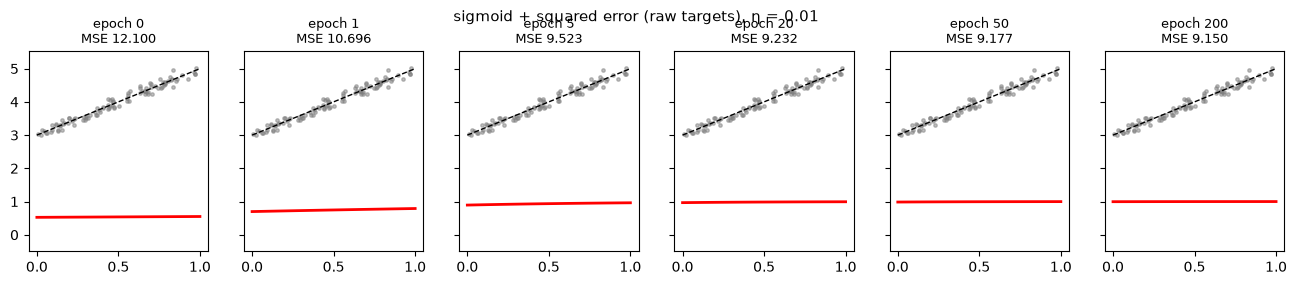

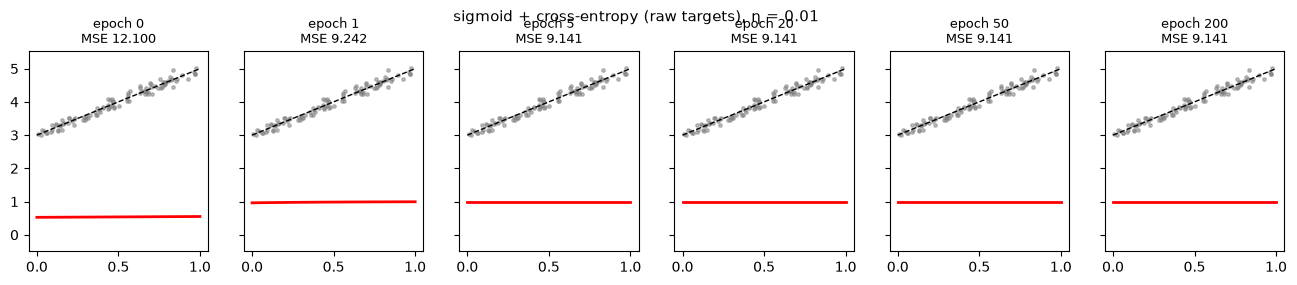

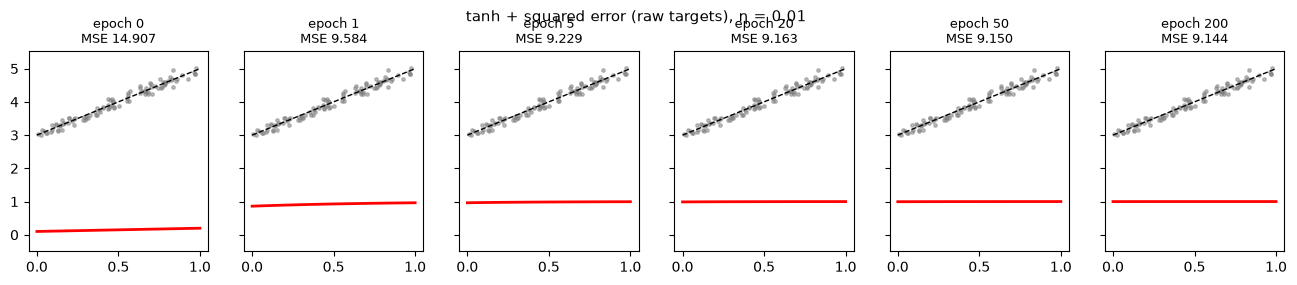

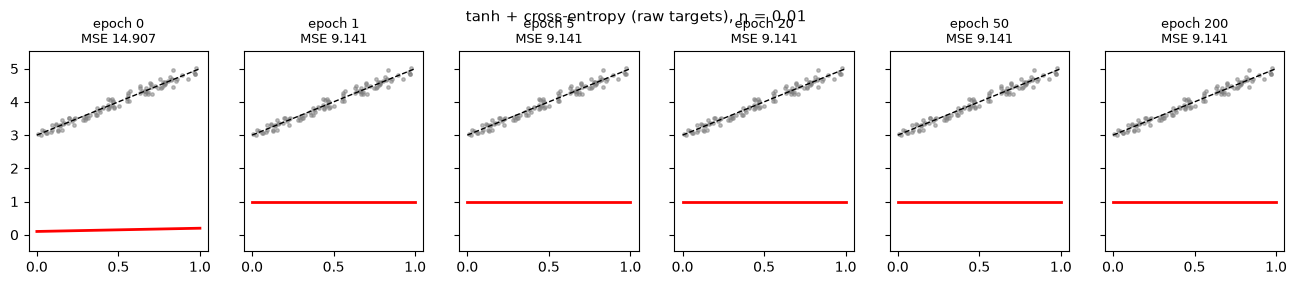

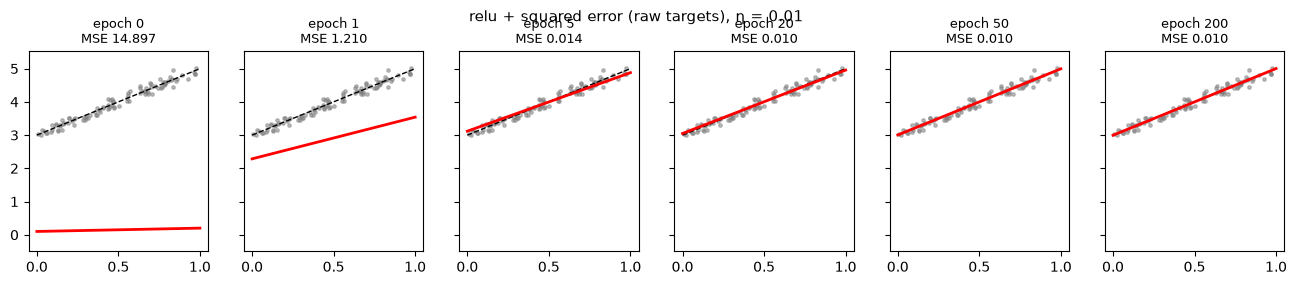

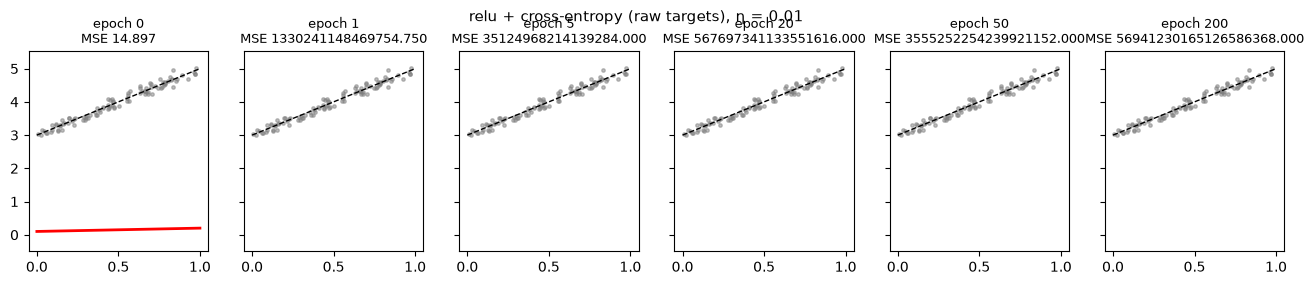

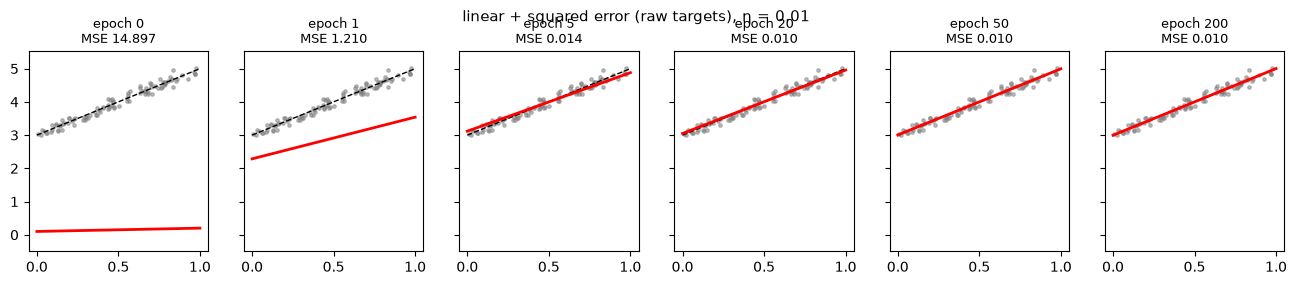

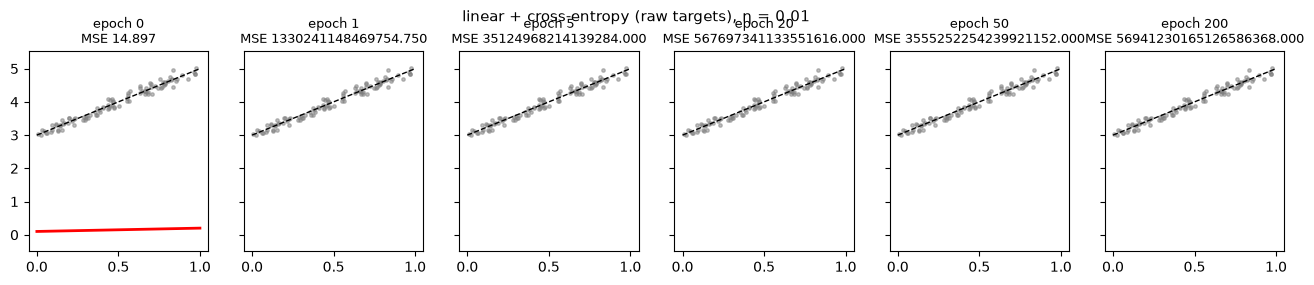

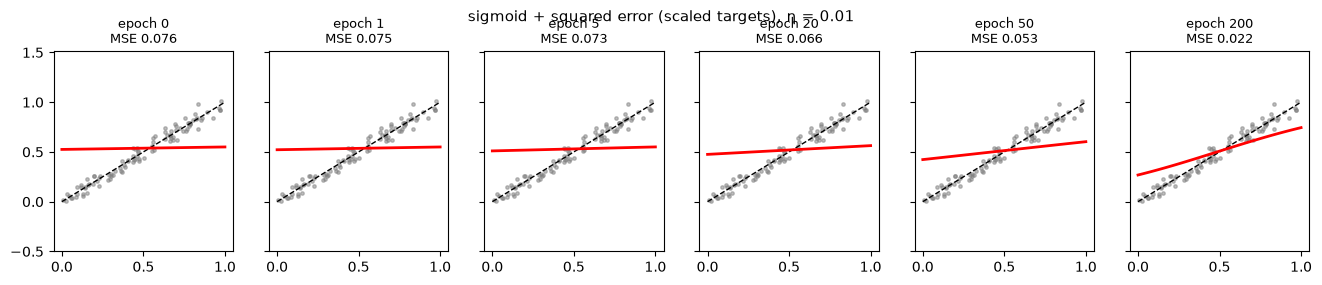

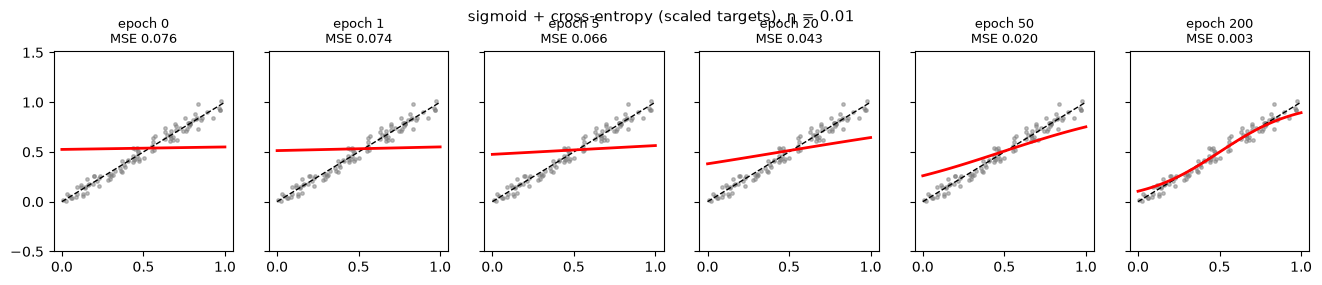

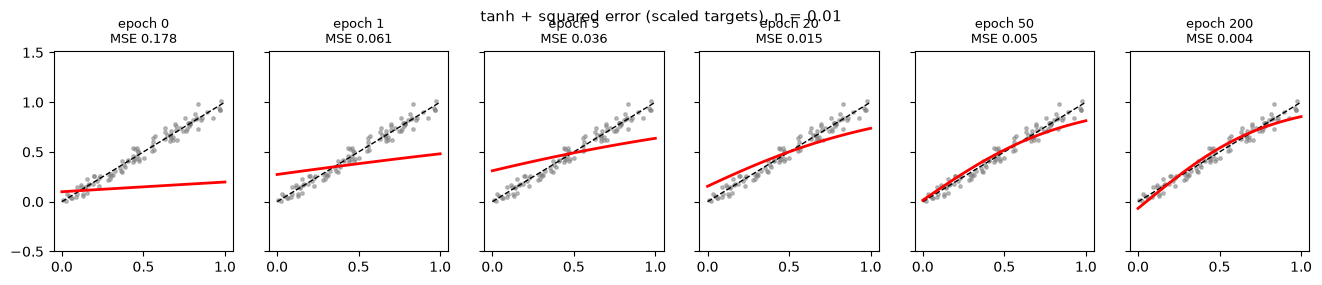

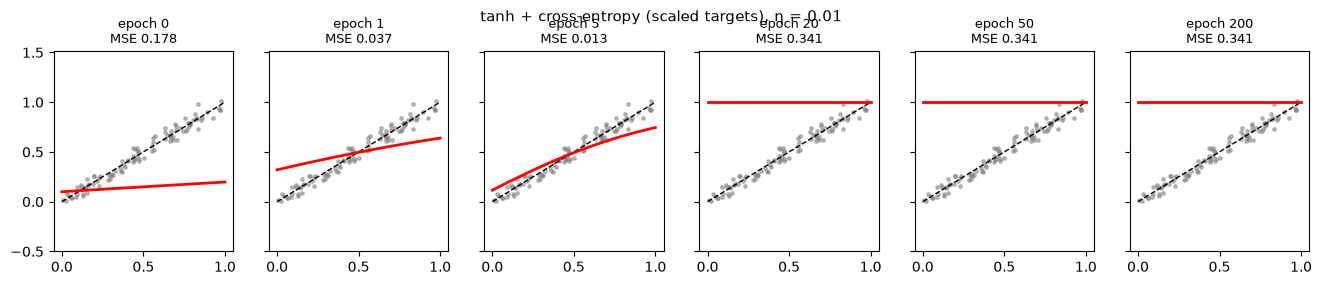

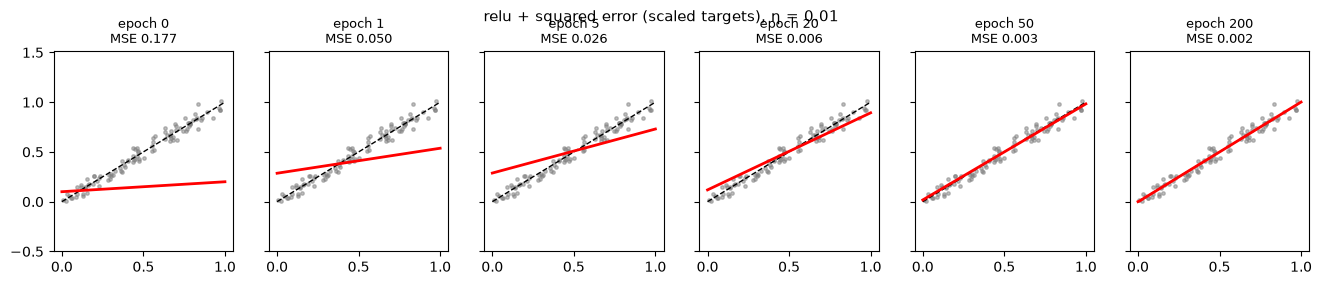

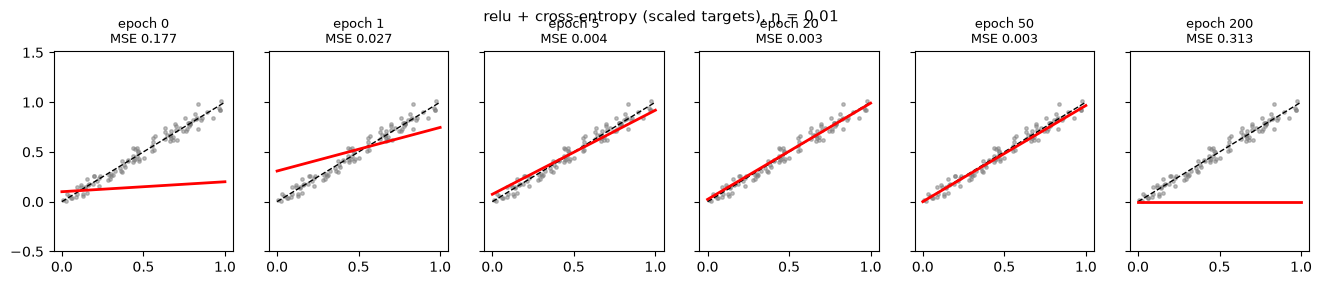

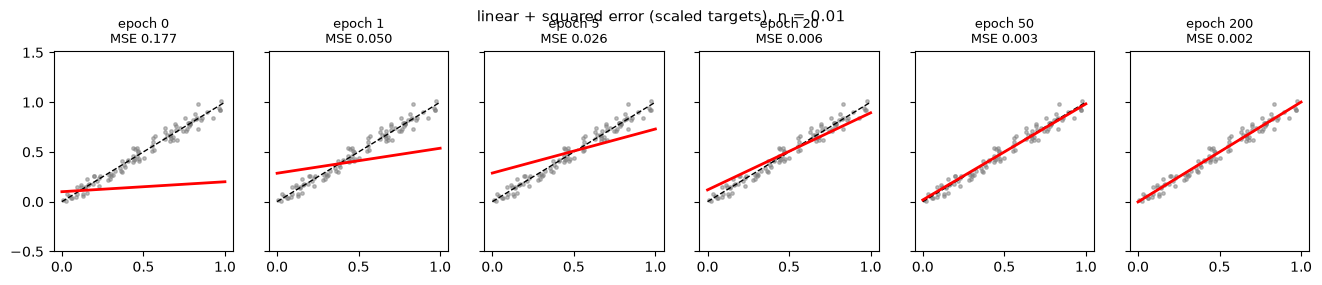

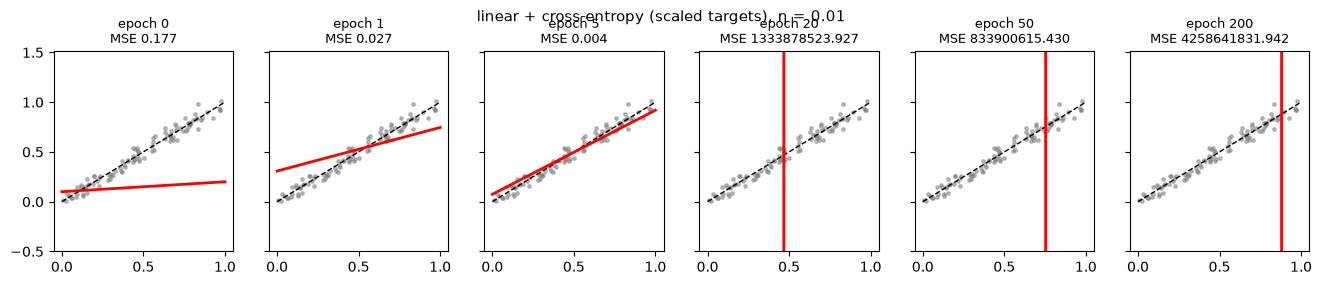

In [22]:
for key in runs9:
    strip_run(key, name='q9a_' + '_'.join(k.replace(' ', '').replace('-', '') for k in key))

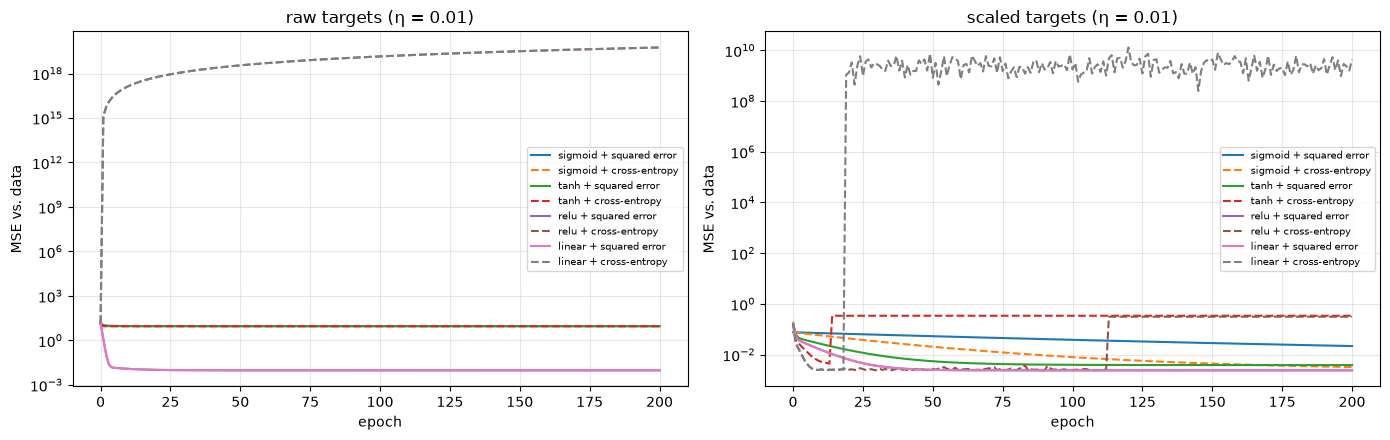

In [23]:
# Learning curves of all combinations
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, tname in zip(axes, TARGETS):
    for (t, aname, cname), h in runs9.items():
        if t != tname:
            continue
        ax.plot(h['mse'], label=f'{aname} + {cname}', ls='-' if cname == 'squared error' else '--')
    ax.set_yscale('log'); ax.set_xlabel('epoch'); ax.set_ylabel('MSE vs. data'); ax.grid(alpha=0.3, which='both')
    ax.set_title(f'{tname} targets (η = {LR9})'); ax.legend(fontsize=7)
plt.tight_layout(); savefig(fig, 'q9b_learning_curves'); plt.show()

### Q9c. Learning rates (ReLU + squared error, raw targets; sigmoid + cross-entropy, scaled targets)

relu     squared error  lr=0.001  w=1.909 b=3.046 final MSE=0.01033 epochs run=200
relu     squared error  lr=0.01   w=2.008 b=2.995 final MSE=0.009589 epochs run=200
relu     squared error  lr=0.1    w=2.008 b=2.999 final MSE=0.009612 epochs run=200
relu     squared error  lr=1      w=1.945 b=2.974 final MSE=0.0125 epochs run=200
relu     squared error  lr=10     w=-24.5 b=-430.3 final MSE=16.09 epochs run=200  (dead ReLU: z <= 0 for every x, all gradients 0)
sigmoid  cross-entropy  lr=0.001  w=1.079 b=-0.4903 final MSE=0.04321 epochs run=200
sigmoid  cross-entropy  lr=0.01   w=4.278 b=-2.145 final MSE=0.003246 epochs run=200
sigmoid  cross-entropy  lr=0.1    w=5.056 b=-2.547 final MSE=0.002651 epochs run=200
sigmoid  cross-entropy  lr=1      w=5.094 b=-2.495 final MSE=0.002787 epochs run=200
sigmoid  cross-entropy  lr=10     w=7.294 b=-3.856 final MSE=0.008619 epochs run=200


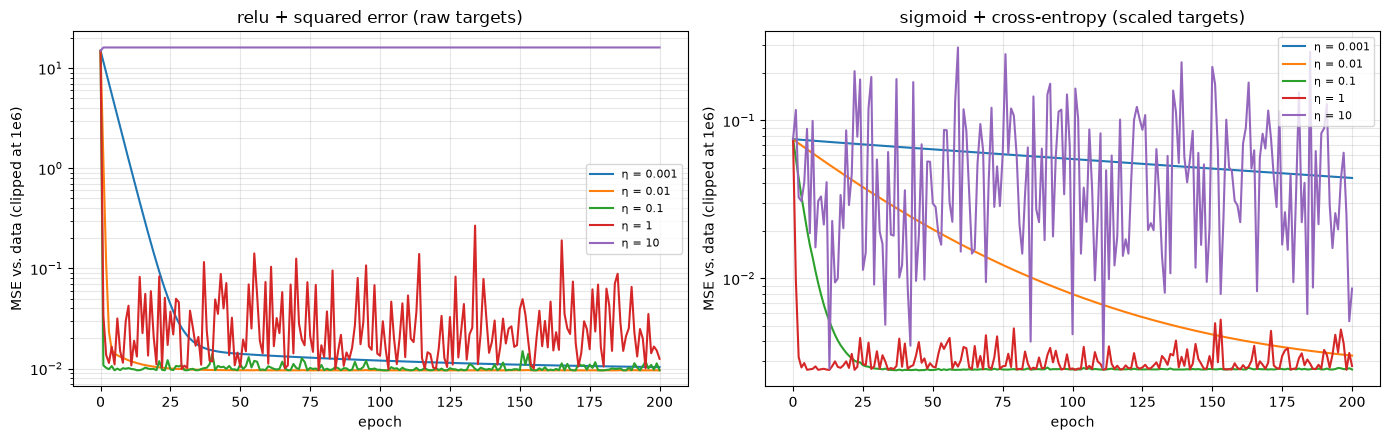

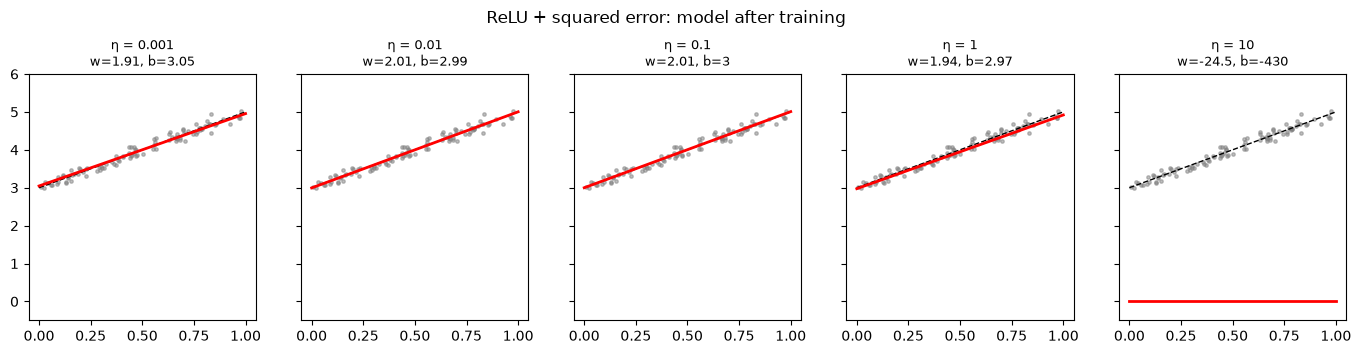

In [24]:
LRS = [0.001, 0.01, 0.1, 1, 10]
lr_runs = {}
for combo in [('raw', 'relu', 'squared error'), ('scaled', 'sigmoid', 'cross-entropy')]:
    tname, aname, cname = combo
    for lr in LRS:
        lr_runs[combo + (lr,)] = run_neuron(x9, TARGETS[tname][0], ACTIVATIONS[aname], COSTS[cname], lr, EPOCHS9)

q9c = []
for (tname, aname, cname, lr), h in lr_runs.items():
    finite = [m for m in h['mse'] if np.isfinite(m)]
    print(f"{aname:8s} {cname:14s} lr={lr:<6} w={h['w'][-1]:.4g} b={h['b'][-1]:.4g} final MSE={h['mse'][-1]:.4g} "
          f"epochs run={len(h['mse']) - 1}" + ('  DIVERGED' if h['diverged'] else '')
          + ('  (dead ReLU: z <= 0 for every x, all gradients 0)' if aname == 'relu' and np.all(h['w'][-1] * x9 + h['b'][-1] <= 0) else ''))
    q9c.append(dict(targets=tname, activation=aname, cost=cname, lr=lr, w=h['w'][-1], b=h['b'][-1],
                    mse_end=h['mse'][-1], epochs=len(h['mse']) - 1, diverged=h['diverged'],
                    mse_curve=[m if np.isfinite(m) else None for m in h['mse']]))
RESULTS['q9c'] = q9c

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, combo in zip(axes, [('raw', 'relu', 'squared error'), ('scaled', 'sigmoid', 'cross-entropy')]):
    for lr in LRS:
        h = lr_runs[combo + (lr,)]
        ax.plot(np.arange(len(h['mse'])), np.clip(h['mse'], None, 1e6), label=f'η = {lr}' + (' (diverged)' if h['diverged'] else ''))
    ax.set_yscale('log'); ax.set_xlabel('epoch'); ax.set_ylabel('MSE vs. data (clipped at 1e6)')
    ax.set_title(f'{combo[1]} + {combo[2]} ({combo[0]} targets)'); ax.grid(alpha=0.3, which='both'); ax.legend(fontsize=8)
plt.tight_layout(); savefig(fig, 'q9c_learning_rates'); plt.show()

# the extreme examples: model after 200 epochs
fig, axes = plt.subplots(1, 5, figsize=(17, 3.2), sharey=True)
for ax, lr in zip(axes, LRS):
    h = lr_runs[('raw', 'relu', 'squared error', lr)]
    ax.scatter(x9, y9, s=6, c='gray', alpha=0.5)
    ax.plot(xs_plot, f_true(xs_plot), 'k--', lw=1)
    if np.isfinite(h['w'][-1]) and abs(h['w'][-1]) < 1e6:
        ax.plot(xs_plot, neuron_predict(xs_plot, h['w'][-1], h['b'][-1], relu_derivative), 'r-', lw=2)
    ax.set_ylim(-0.5, 6)
    ax.set_title(f"η = {lr}\nw={h['w'][-1]:.3g}, b={h['b'][-1]:.3g}" + ('\nDIVERGED' if h['diverged'] else ''), fontsize=9)
fig.suptitle('ReLU + squared error: model after training', y=1.08)
savefig(fig, 'q9c_models'); plt.show()

### Q9d. Gradients per epoch
`train_neuron(..., return_gradients=True)` returns $\partial C/\partial w$ and $\partial C/\partial b$ for every call.
Per epoch we plot (left) the **mean** gradient over the 100 records, which is the full-batch gradient, and
(right) the **mean absolute** per-record gradient.

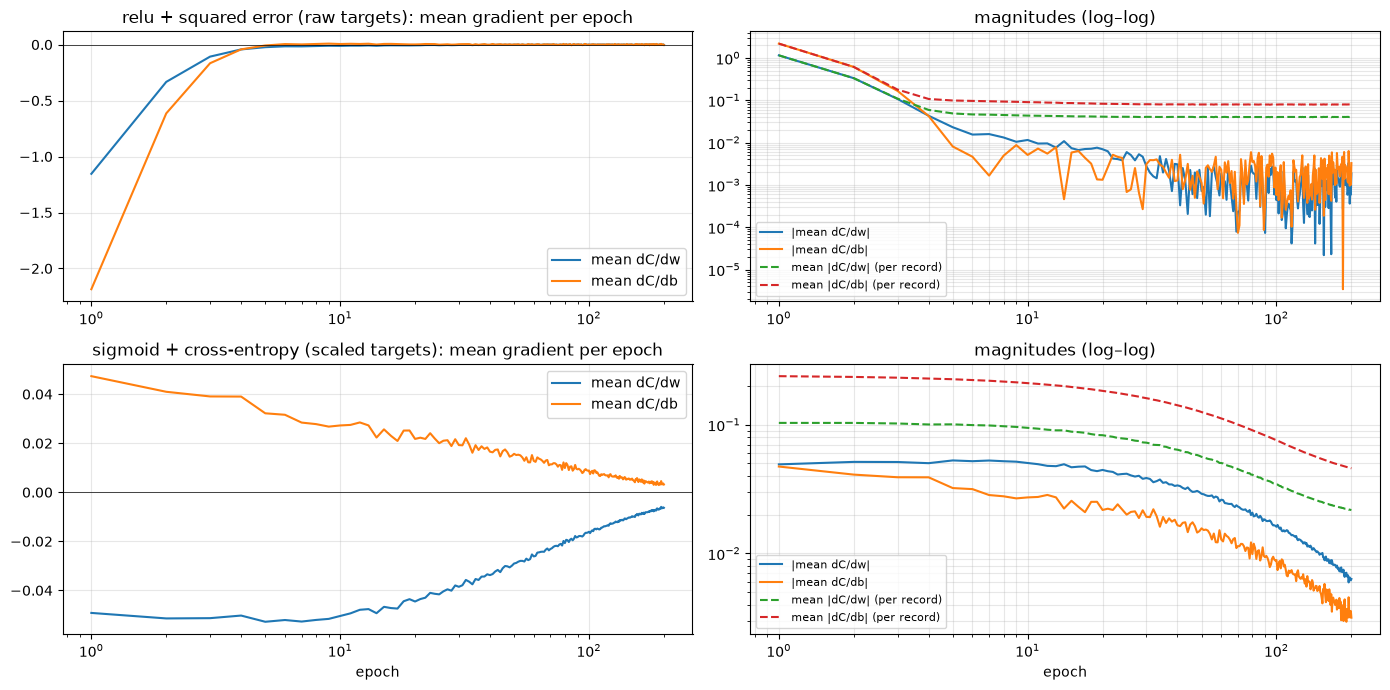

epoch   1: mean dC/dw=-1.15438  mean dC/db=-2.18529  mean|dC/dw|=1.15438  mean|dC/db|=2.18529
epoch   2: mean dC/dw=-0.33315  mean dC/db=-0.61452  mean|dC/dw|=0.33315  mean|dC/db|=0.61452
epoch   5: mean dC/dw=-0.02310  mean dC/db=-0.00809  mean|dC/dw|=0.04895  mean|dC/db|=0.09895
epoch  10: mean dC/dw=-0.01154  mean dC/db= 0.00512  mean|dC/dw|=0.04347  mean|dC/db|=0.09039
epoch  20: mean dC/dw=-0.00697  mean dC/db= 0.00133  mean|dC/dw|=0.04112  mean|dC/db|=0.08306
epoch  50: mean dC/dw=-0.00072  mean dC/db= 0.00111  mean|dC/dw|=0.04033  mean|dC/db|=0.07969
epoch 100: mean dC/dw= 0.00044  mean dC/db= 0.00058  mean|dC/dw|=0.04000  mean|dC/db|=0.07933
epoch 200: mean dC/dw=-0.00187  mean dC/db=-0.00328  mean|dC/dw|=0.04067  mean|dC/db|=0.07992


In [25]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7))
for row, key in enumerate([('raw', 'relu', 'squared error'), ('scaled', 'sigmoid', 'cross-entropy')]):
    h = runs9[key]
    ep = np.arange(1, len(h['grad_w']) + 1)
    ax = axes[row, 0]
    ax.plot(ep, h['grad_w'], label='mean dC/dw'); ax.plot(ep, h['grad_b'], label='mean dC/db')
    ax.axhline(0, color='k', lw=0.5); ax.set_xscale('log'); ax.grid(alpha=0.3)
    ax.set_title(f'{key[1]} + {key[2]} ({key[0]} targets): mean gradient per epoch'); ax.legend()
    ax = axes[row, 1]
    ax.plot(ep, np.abs(h['grad_w']), label='|mean dC/dw|'); ax.plot(ep, np.abs(h['grad_b']), label='|mean dC/db|')
    ax.plot(ep, h['abs_grad_w'], '--', label='mean |dC/dw| (per record)'); ax.plot(ep, h['abs_grad_b'], '--', label='mean |dC/db| (per record)')
    ax.set_xscale('log'); ax.set_yscale('log'); ax.grid(alpha=0.3, which='both'); ax.legend(fontsize=8)
    ax.set_title('magnitudes (log–log)')
for ax in axes[1]:
    ax.set_xlabel('epoch')
plt.tight_layout(); savefig(fig, 'q9d_gradients'); plt.show()

h = runs9[('raw', 'relu', 'squared error')]
for e in (1, 2, 5, 10, 20, 50, 100, 200):
    print(f"epoch {e:3d}: mean dC/dw={h['grad_w'][e-1]: .5f}  mean dC/db={h['grad_b'][e-1]: .5f}  "
          f"mean|dC/dw|={h['abs_grad_w'][e-1]:.5f}  mean|dC/db|={h['abs_grad_b'][e-1]:.5f}")
RESULTS['q9d'] = {k: dict(grad_w=v['grad_w'], grad_b=v['grad_b'], abs_grad_w=v['abs_grad_w'], abs_grad_b=v['abs_grad_b'])
                  for k, v in [('relu_mse_raw', runs9[('raw', 'relu', 'squared error')]),
                               ('sigmoid_ce_scaled', runs9[('scaled', 'sigmoid', 'cross-entropy')])]}

### Q9e. Linear activation
The rows `linear` in the table above use $g(z) = z$. With squared error this is ordinary least-squares linear
regression trained by SGD; we compare it directly with ReLU and with the closed-form least-squares fit.

In [26]:
A = np.c_[x9, np.ones_like(x9)]
w_ls, b_ls = np.linalg.lstsq(A, y9, rcond=None)[0]
print(f'closed-form least squares: w={w_ls:.4f}, b={b_ls:.4f}, MSE={np.mean((A @ [w_ls, b_ls] - y9) ** 2):.5f}')
for key in [('raw', 'linear', 'squared error'), ('raw', 'relu', 'squared error'), ('raw', 'linear', 'cross-entropy')]:
    h = runs9[key]
    print(f'{key}: w={h["w"][-1]:.4f}, b={h["b"][-1]:.4f}, MSE={h["mse"][-1]:.5f}')
RESULTS['q9e'] = dict(w_ls=float(w_ls), b_ls=float(b_ls))

closed-form least squares: w=2.0077, b=2.9949, MSE=0.00959
('raw', 'linear', 'squared error'): w=2.0076, b=2.9949, MSE=0.00959
('raw', 'relu', 'squared error'): w=2.0076, b=2.9949, MSE=0.00959
('raw', 'linear', 'cross-entropy'): w=3190090503.7946, b=5943119207.8645, MSE=56941230165126586368.00000


In [27]:
def to_jsonable(o):
    if isinstance(o, dict):
        return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_jsonable(v) for v in o]
    if isinstance(o, (np.floating, np.integer)):
        o = o.item()
    if isinstance(o, float) and not np.isfinite(o):
        return None
    return o

with open('results/results.json', 'w') as fh:
    json.dump(to_jsonable(RESULTS), fh, indent=1)
print('saved results/results.json')

saved results/results.json
